# Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
file_path = "/content/drive/MyDrive/Dataset/BDCBC7196_Hematology_Dataset.csv"
df = pd.read_csv(file_path)

print("Shape:", df.shape)
display(df.head())

Shape: (7196, 17)


,Gender,Age,Hb,RBC,WBC,PLATELETS,LYMP,MONO,HCT,MCV,MCH,MCHC,RDW,PDW,MPV,PCT,Diagnosis
0,0,45,12.1,4.25,12300,404000.0,29.0,4.6,36.2,85.2,28.4,33.4,14.0,13.6,10.2,0.410,Anemia of Chronic Disease
1,0,58,12.3,4.34,12000,392000.0,30.0,5.1,37.1,85.5,28.3,33.1,14.0,13.8,10.2,0.390,Anemia of Chronic Disease
2,0,49,12.6,4.35,11300,387000.0,23.5,7.0,38.2,87.9,28.9,32.9,14.1,14.9,10.7,0.410,Anemia of Chronic Disease
3,0,43,12.0,4.30,5000,298000.0,43.1,6.5,35.8,83.4,27.9,33.5,13.7,15.3,8.5,0.254,Anemia of Chronic Disease
4,0,29,11.4,4.36,8720,267000.0,31.1,5.9,35.1,80.4,26.1,32.5,14.0,15.6,8.3,0.222,Anemia of Chronic Disease


# EDA

In [4]:
print("Dataset Info:")
print(df.info())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe().T)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7196 entries, 0 to 7195
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Gender     7196 non-null   int64  
 1   Age        7196 non-null   int64  
 2   Hb         7196 non-null   float64
 3   RBC        7196 non-null   float64
 4   WBC        7196 non-null   int64  
 5   PLATELETS  7196 non-null   float64
 6   LYMP       7196 non-null   float64
 7   MONO       7196 non-null   float64
 8   HCT        7196 non-null   float64
 9   MCV        7196 non-null   float64
 10  MCH        7196 non-null   float64
 11  MCHC       7196 non-null   float64
 12  RDW        7196 non-null   float64
 13  PDW        7196 non-null   float64
 14  MPV        7196 non-null   float64
 15  PCT        7196 non-null   float64
 16  Diagnosis  7196 non-null   object 
dtypes: float64(13), int64(3), object(1)
memory usage: 955.8+ KB
None

Data Types:
Gender         int64
Age            

,count,mean,std,min,25%,50%,75%,max
Gender,7196.0,0.523902,0.499463,0.000000,0.000,1.00,1.00,1.000000e+00
Age,7196.0,41.201501,12.462847,20.000000,31.000,41.00,51.00,6.900000e+01
Hb,7196.0,12.689661,3.172279,2.100000,10.800,12.10,13.60,2.500000e+01
RBC,7196.0,4.145006,1.222941,1.000000,3.570,4.30,4.97,9.970040e+00
WBC,7196.0,32747.217899,61977.439066,100.000000,8400.000,10990.00,14530.00,2.998900e+05
PLATELETS,7196.0,371416.553527,315569.617324,5382.000000,229000.000,297000.00,382000.00,1.989770e+06
LYMP,7196.0,37.781048,17.937115,2.000000,27.100,32.70,41.00,9.500000e+01
MONO,7196.0,6.794056,4.237292,0.100000,5.000,5.90,6.80,2.997000e+01
HCT,7196.0,36.365997,6.814388,5.000000,33.100,36.70,40.30,7.408967e+01
MCV,7196.0,81.786891,11.934138,50.000000,75.515,81.00,87.70,1.300000e+02



Missing Values:
Gender       0
Age          0
Hb           0
RBC          0
WBC          0
PLATELETS    0
LYMP         0
MONO         0
HCT          0
MCV          0
MCH          0
MCHC         0
RDW          0
PDW          0
MPV          0
PCT          0
Diagnosis    0
dtype: int64

Duplicate Rows: 1


Diagnosis
Anemia of Chronic Disease    1399
Normocytic Anemia            1264
Bacterial Infections         1160
Thrombocytosis                621
Infectious Mononucleosis      472
Beta-Thalassemia Minor        432
Normal                        415
Viral Infections              323
Leukopenia                    233
Microcytic Anemia             232
Iron Deficiency               230
Leukocytosis                  171
Thrombocytopenia              116
Chronic Leukemias              99
Polycythemia Vera              29
Name: count, dtype: int64


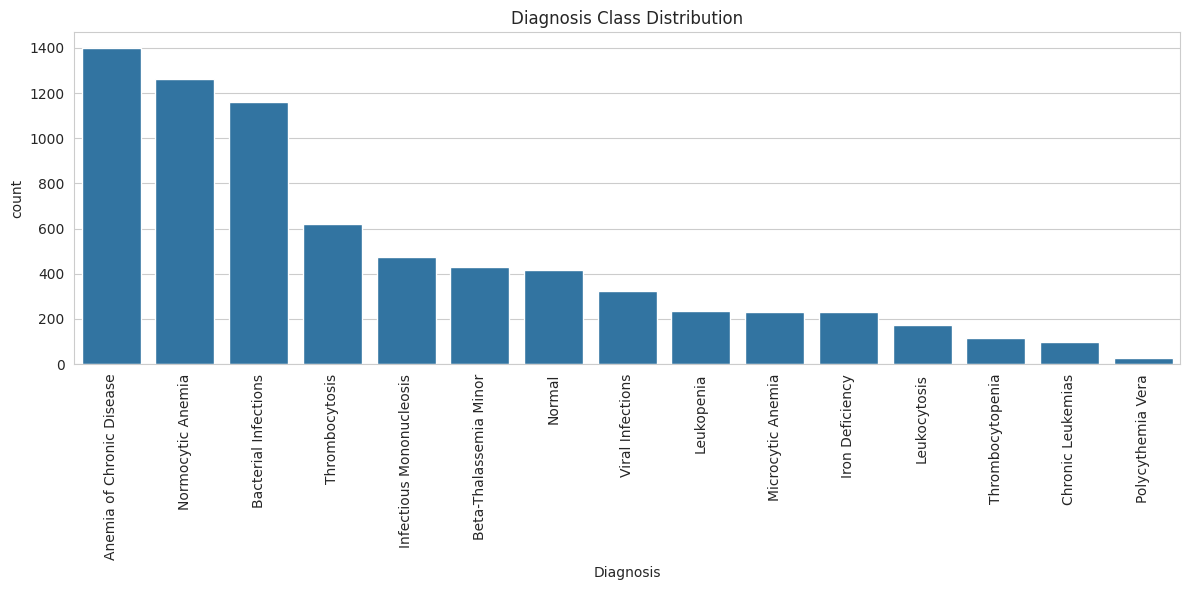

,proportion
Diagnosis,
Anemia of Chronic Disease,19.44
Normocytic Anemia,17.57
Bacterial Infections,16.12
Thrombocytosis,8.63
Infectious Mononucleosis,6.56
Beta-Thalassemia Minor,6.00
Normal,5.77
Viral Infections,4.49
Leukopenia,3.24


In [5]:
print(df["Diagnosis"].value_counts())

plt.figure(figsize=(12,6))
sns.countplot(data=df, x="Diagnosis", order=df["Diagnosis"].value_counts().index)
plt.xticks(rotation=90)
plt.title("Diagnosis Class Distribution")
plt.tight_layout()
plt.show()

class_percent = df["Diagnosis"].value_counts(normalize=True) * 100
display(class_percent.round(2))

In [6]:
target_col = "Diagnosis"
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Numeric Columns:")
print(numeric_cols)

print("\nTarget Column:")
print(target_col)

Numeric Columns:
['Gender', 'Age', 'Hb', 'RBC', 'WBC', 'PLATELETS', 'LYMP', 'MONO', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW', 'PDW', 'MPV', 'PCT']

Target Column:
Diagnosis


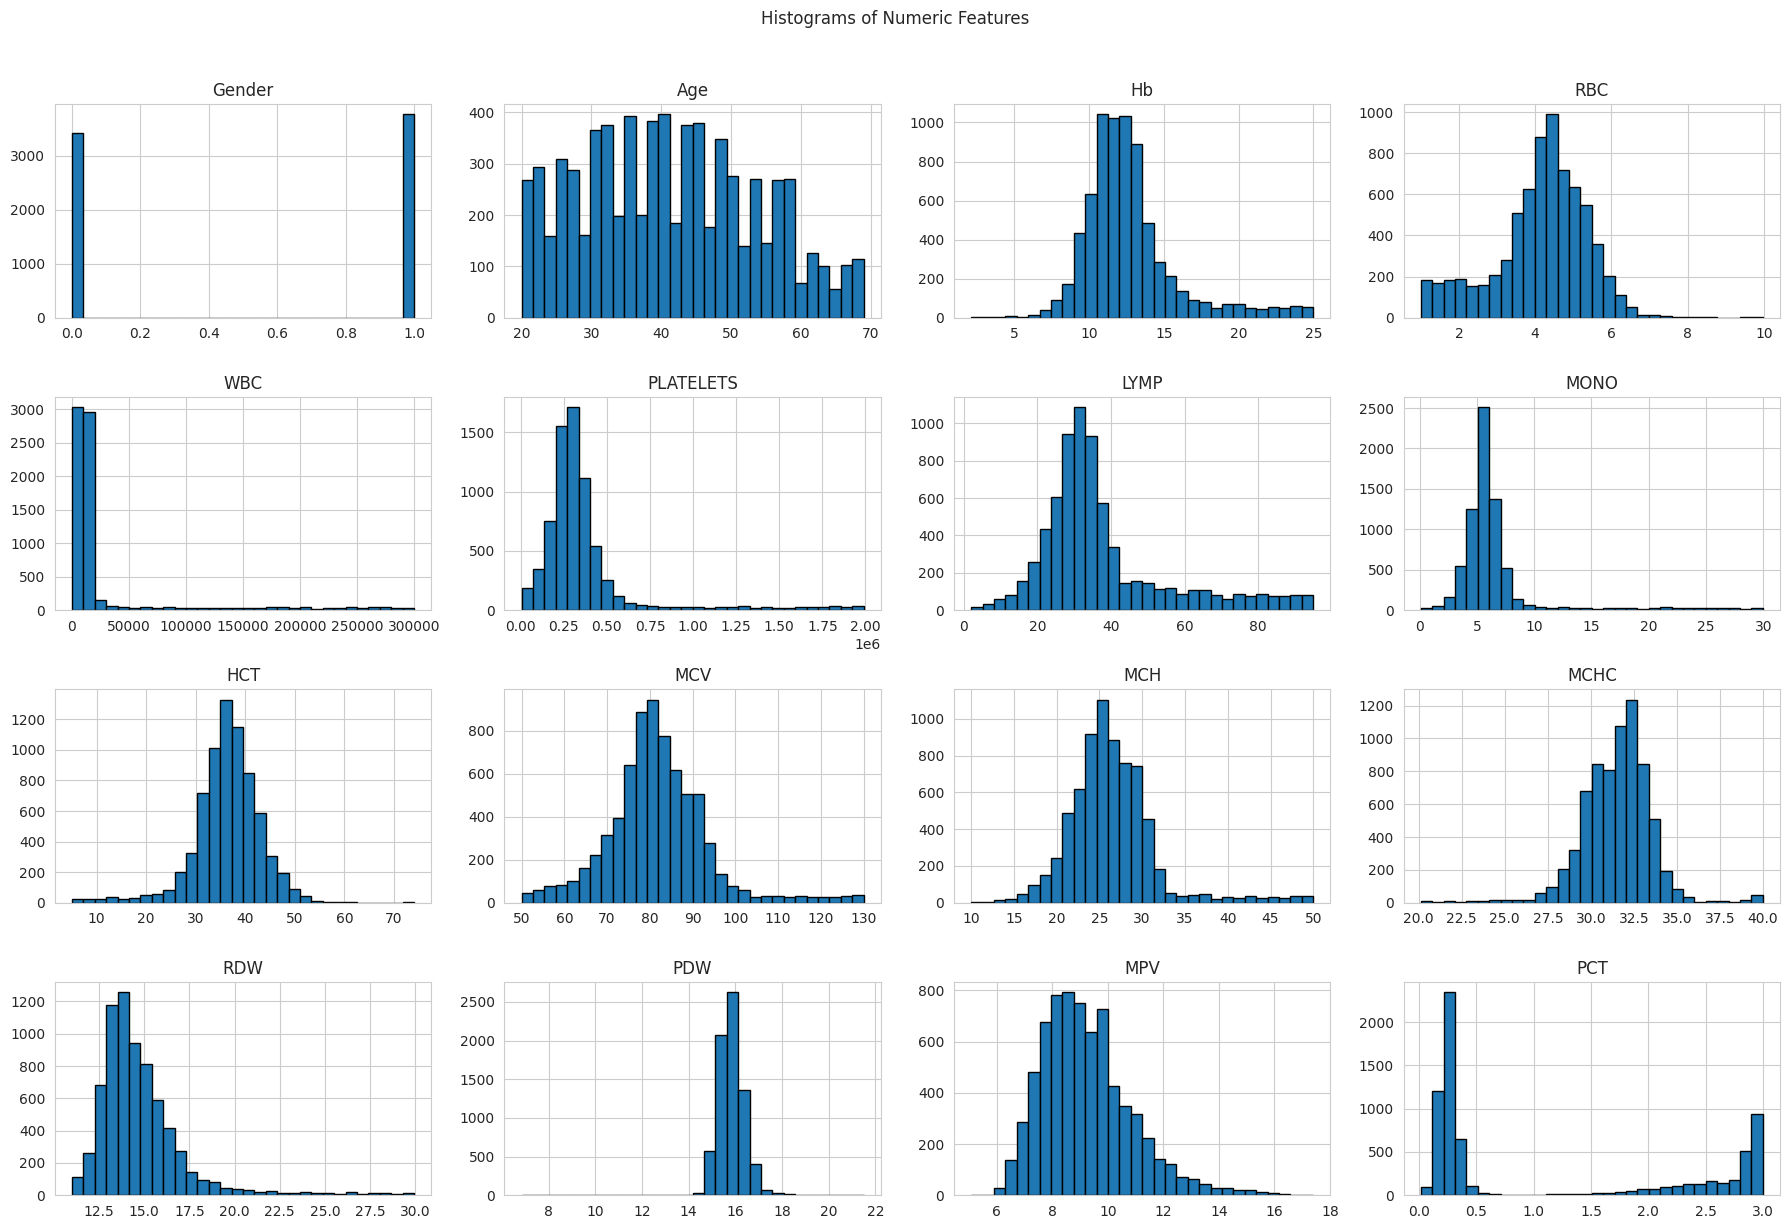

In [7]:
df[numeric_cols].hist(figsize=(18,12), bins=30, edgecolor="black")
plt.suptitle("Histograms of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()

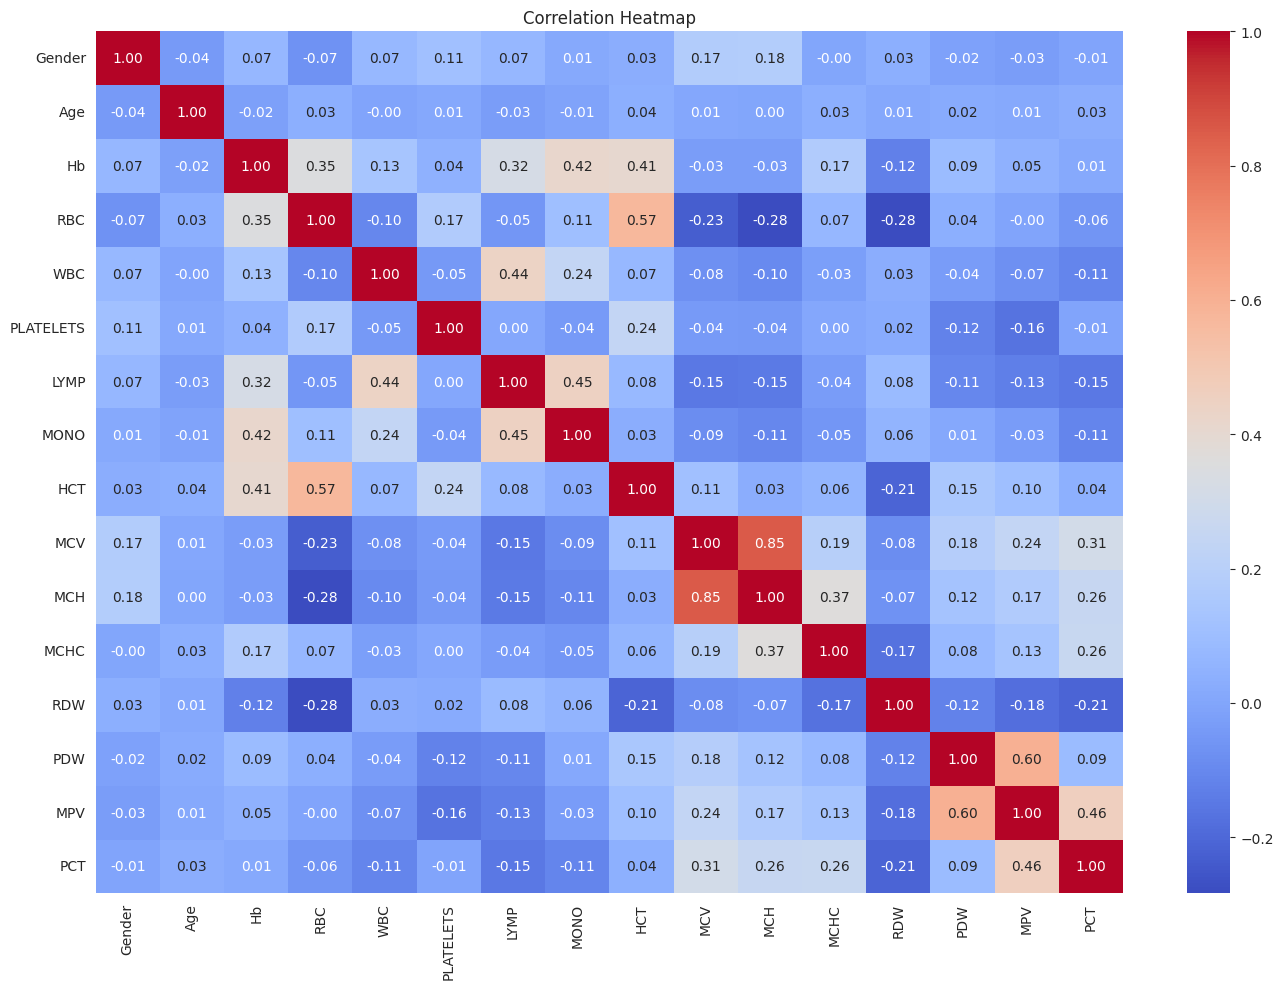

In [8]:
plt.figure(figsize=(14,10))
corr = df[numeric_cols].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=False)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

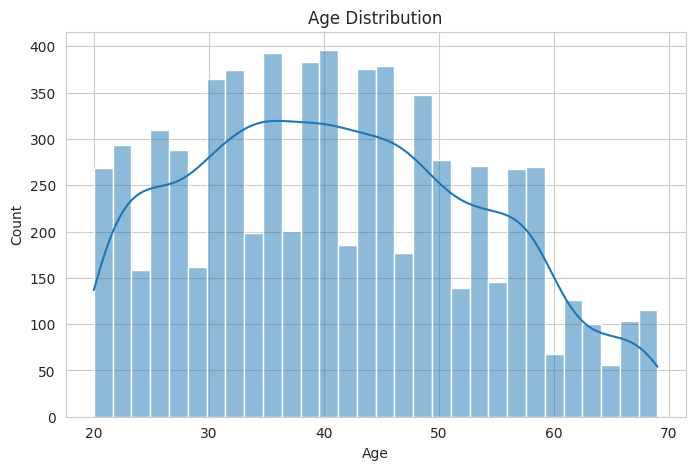

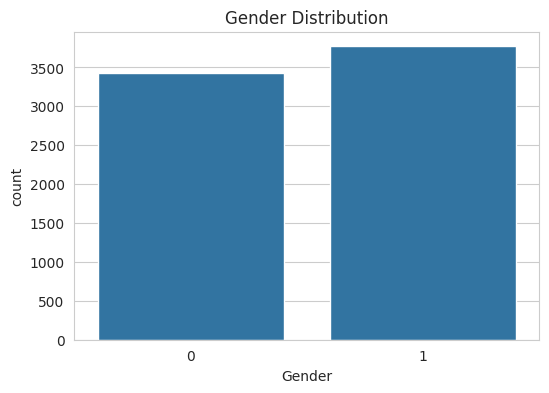

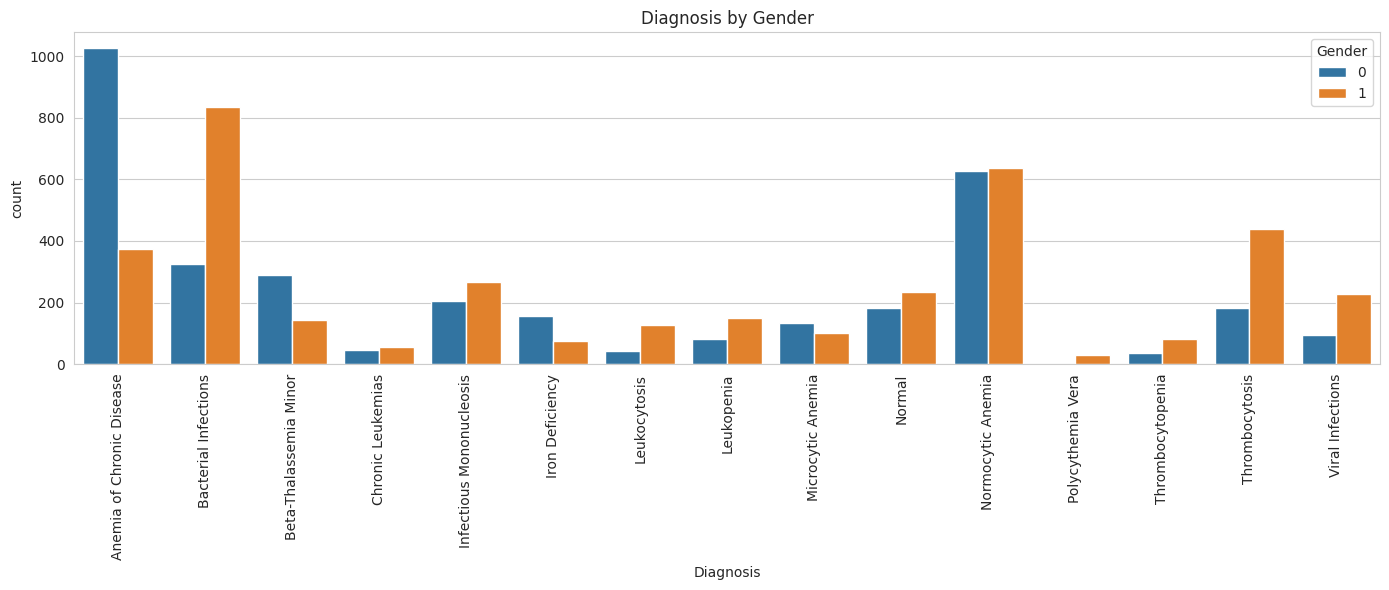

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df["Age"], bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Gender")
plt.title("Gender Distribution")
plt.show()

plt.figure(figsize=(14,6))
sns.countplot(data=df, x="Diagnosis", hue="Gender")
plt.xticks(rotation=90)
plt.title("Diagnosis by Gender")
plt.tight_layout()
plt.show()

# Preprocessing

In [10]:
df = df.drop_duplicates().reset_index(drop=True)

X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
le = label_encoder

print("Encoded classes:")
for i, cls in enumerate(label_encoder.classes_):
    print(i, "->", cls)

Encoded classes:
0 -> Anemia of Chronic Disease
1 -> Bacterial Infections
2 -> Beta-Thalassemia Minor
3 -> Chronic Leukemias
4 -> Infectious Mononucleosis
5 -> Iron Deficiency
6 -> Leukocytosis
7 -> Leukopenia
8 -> Microcytic Anemia
9 -> Normal
10 -> Normocytic Anemia
11 -> Polycythemia Vera
12 -> Thrombocytopenia
13 -> Thrombocytosis
14 -> Viral Infections


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (5756, 16)
X_test shape: (1439, 16)
y_train shape: (5756,)
y_test shape: (1439,)


In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled train shape: (5756, 16)
Scaled test shape: (1439, 16)


# Feature Extraction

In [13]:
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original feature count:", X_train.shape[1])
print("PCA feature count:", X_train_pca.shape[1])
print("Explained variance ratio sum:", pca.explained_variance_ratio_.sum())

Original feature count: 16
PCA feature count: 13
Explained variance ratio sum: 0.9595917041453691


In [14]:
# =========================================================
# Enhanced evaluation function for CLASSICAL / ML models
# -> Accuracy, Precision, Recall, F1
# -> Classification Report
# -> Confusion Matrix
# -> ROC Curve (multi-class, One-vs-Rest)
# =========================================================
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# store results of every model for final comparison
results_summary = {}

def evaluate_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Probabilities for ROC (fallback to decision_function if needed)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
    else:
        y_score = None

    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    results_summary[name] = {"Accuracy": acc, "Precision": prec,
                             "Recall": rec, "F1": f1}

    print("\n===============================")
    print(name)
    print("===============================")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}")

    print("\nClassification Report")
    print(classification_report(y_test, y_pred,
                                target_names=le.classes_,
                                zero_division=0))

    # -------- Confusion Matrix --------
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, cmap="Blues", annot=True, fmt="d",
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # -------- ROC curve (One-vs-Rest, multi-class) --------
    if y_score is not None:
        classes = np.unique(y_encoded)
        y_test_bin = label_binarize(y_test, classes=classes)
        n_classes = y_test_bin.shape[1]

        if y_score.ndim == 1:  # binary case
            y_score = np.vstack([1 - y_score, y_score]).T

        fpr, tpr, roc_auc = {}, {}, {}
        for i in range(n_classes):
            fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
            roc_auc[i] = auc(fpr[i], tpr[i])

        # micro-average
        fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(),
                                                  y_score.ravel())
        roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

        plt.figure(figsize=(10, 7))
        plt.plot(fpr["micro"], tpr["micro"],
                 label=f"micro-average ROC (AUC = {roc_auc['micro']:.3f})",
                 linestyle=":", linewidth=3)
        for i in range(n_classes):
            plt.plot(fpr[i], tpr[i],
                     label=f"{le.classes_[i]} (AUC = {roc_auc[i]:.3f})")
        plt.plot([0, 1], [0, 1], "k--", lw=1)
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title(f"{name} - ROC Curve (One-vs-Rest)")
        plt.legend(loc="lower right", fontsize=8)
        plt.tight_layout()
        plt.show()


# Deep Learning Models

Prepare data and reusable evaluation helpers for ANN, CNN, RNN, LSTM, GRU, BiLSTM.

In [15]:
# -----------------------------------------------------------
# Deep Learning setup  (tuned)
# -----------------------------------------------------------
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import MinMaxScaler

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

num_classes = len(np.unique(y_encoded))
print("Number of classes:", num_classes)
print("Classes:", le.classes_)

# One-hot targets
y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_test_cat  = to_categorical(y_test,  num_classes=num_classes)

# ANN uses StandardScaler features
X_train_ann = X_train_scaled
X_test_ann  = X_test_scaled

# Sequence models: MinMax-scaled features reshaped to (samples, steps, 1)
mm_scaler = MinMaxScaler()
X_train_mm = mm_scaler.fit_transform(X_train)
X_test_mm  = mm_scaler.transform(X_test)

X_train_seq = X_train_mm.reshape(X_train_mm.shape[0], X_train_mm.shape[1], 1)
X_test_seq  = X_test_mm.reshape(X_test_mm.shape[0],  X_test_mm.shape[1], 1)

print("ANN input shape :", X_train_ann.shape)
print("SEQ input shape :", X_train_seq.shape)
print("y_train_cat     :", y_train_cat.shape)

# ---- class weights for imbalance ----
class_weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {i: w for i, w in enumerate(class_weights_arr)}
print("\nClass weights (first 5):",
      {k: round(v, 3) for k, v in list(class_weight_dict.items())[:5]})

# ---- shared training hyperparameters ----
EPOCHS     = 150
BATCH_SIZE = 64
VAL_SPLIT  = 0.2

def make_callbacks(patience_es=20, patience_lr=7):
    return [
        callbacks.EarlyStopping(
            monitor="val_loss",
            patience=patience_es,
            restore_best_weights=True,
            verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=patience_lr,
            min_lr=1e-6,
            verbose=1
        ),
    ]


Number of classes: 15
Classes: ['Anemia of Chronic Disease' 'Bacterial Infections'
 'Beta-Thalassemia Minor' 'Chronic Leukemias' 'Infectious Mononucleosis'
 'Iron Deficiency' 'Leukocytosis' 'Leukopenia' 'Microcytic Anemia'
 'Normal' 'Normocytic Anemia' 'Polycythemia Vera' 'Thrombocytopenia'
 'Thrombocytosis' 'Viral Infections']
ANN input shape : (5756, 16)
SEQ input shape : (5756, 16, 1)
y_train_cat     : (5756, 15)

Class weights (first 5): {0: np.float64(0.343), 1: np.float64(0.414), 2: np.float64(1.109), 3: np.float64(4.857), 4: np.float64(1.015)}


In [16]:
# -----------------------------------------------------------
# Unified evaluator for Keras deep learning models.
# Produces:
#   * Accuracy / Precision / Recall / F1
#   * Classification report
#   * Confusion matrix
#   * Training vs Validation accuracy & loss curves
#   * ROC curve (One-vs-Rest, per class + micro-average)
# -----------------------------------------------------------
def evaluate_dl_model(model, history, X_te, y_te_cat, y_te_int, name):
    # ---- predictions ----
    y_prob = model.predict(X_te, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    acc  = accuracy_score(y_te_int, y_pred)
    prec = precision_score(y_te_int, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_te_int, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_te_int, y_pred, average='weighted', zero_division=0)

    results_summary[name] = {"Accuracy": acc, "Precision": prec,
                             "Recall": rec, "F1": f1}

    print("\n===============================")
    print(name)
    print("===============================")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1 Score : {f1:.4f}")

    print("\nClassification Report")
    print(classification_report(y_te_int, y_pred,
                                target_names=le.classes_,
                                zero_division=0))

    # ---- Confusion matrix ----
    cm = confusion_matrix(y_te_int, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, cmap="Blues", annot=True, fmt="d",
                xticklabels=le.classes_, yticklabels=le.classes_)
    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # ---- Training curves ----
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(h.get('accuracy', []), label='Train Accuracy')
    if 'val_accuracy' in h:
        axes[0].plot(h['val_accuracy'], label='Val Accuracy')
    axes[0].set_title(f"{name} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(h.get('loss', []), label='Train Loss')
    if 'val_loss' in h:
        axes[1].plot(h['val_loss'], label='Val Loss')
    axes[1].set_title(f"{name} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # ---- ROC curve (One-vs-Rest) ----
    n_classes = y_te_cat.shape[1]
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_te_cat[:, i], y_prob[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["micro"], tpr["micro"], _ = roc_curve(y_te_cat.ravel(),
                                              y_prob.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    plt.figure(figsize=(10, 7))
    plt.plot(fpr["micro"], tpr["micro"],
             label=f"micro-average ROC (AUC = {roc_auc['micro']:.3f})",
             linestyle=":", linewidth=3)
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i],
                 label=f"{le.classes_[i]} (AUC = {roc_auc[i]:.3f})")
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} - ROC Curve (One-vs-Rest)")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()


# Common training settings
EPOCHS     = 60
BATCH_SIZE = 32
VAL_SPLIT  = 0.2

early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)


## ANN (Artificial Neural Network)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 256)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 15)             │           495 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,871 (194.81 KB)

 Trainable params: 48,975 (191.31 KB)

 Non-trainable params: 896 (3.50 KB)

Epoch 1/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 14s 17ms/step - accuracy: 0.3186 - loss: 2.1753 - val_accuracy: 0.5469 - val_loss: 1.9684 - learning_rate: 0.0010
Epoch 2/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5960 - loss: 1.2708 - val_accuracy: 0.7309 - val_loss: 1.0218 - learning_rate: 0.0010
Epoch 3/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6664 - loss: 0.9928 - val_accuracy: 0.7917 - val_loss: 0.6883 - learning_rate: 0.0010
Epoch 4/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.7018 - loss: 0.8675 - val_accuracy: 0.7891 - val_loss: 0.6457 - learning_rate: 0.0010
Epoch 5/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7148 - loss: 0.7956 - val_accuracy: 0.8203 - val_loss: 0.5484 - learning_rate: 0.0010
Epoch 6/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7385 - loss: 0.7149 - val_accuracy: 0.8385 - val_loss: 0.5062 - learning_rate: 0.0010
Epoch 7/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7487 - loss: 0

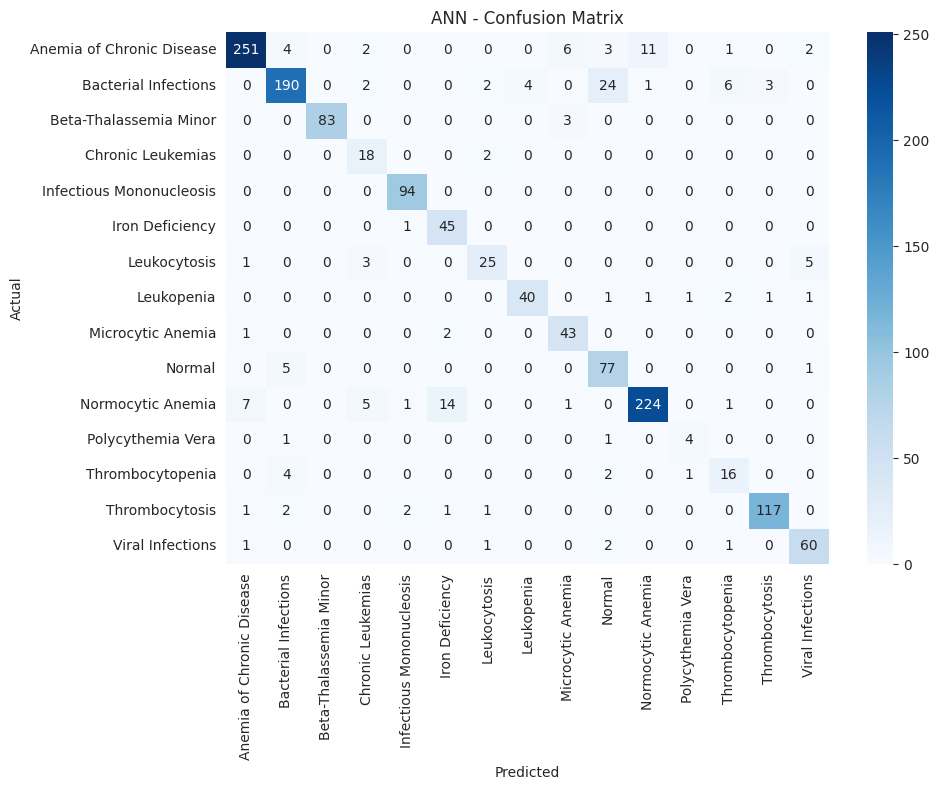

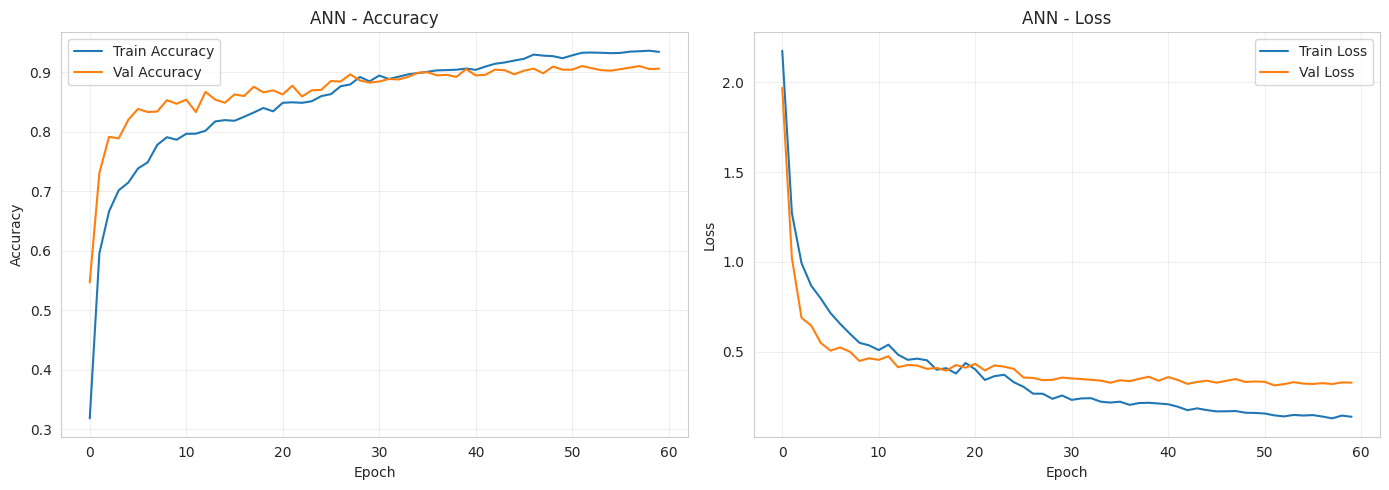

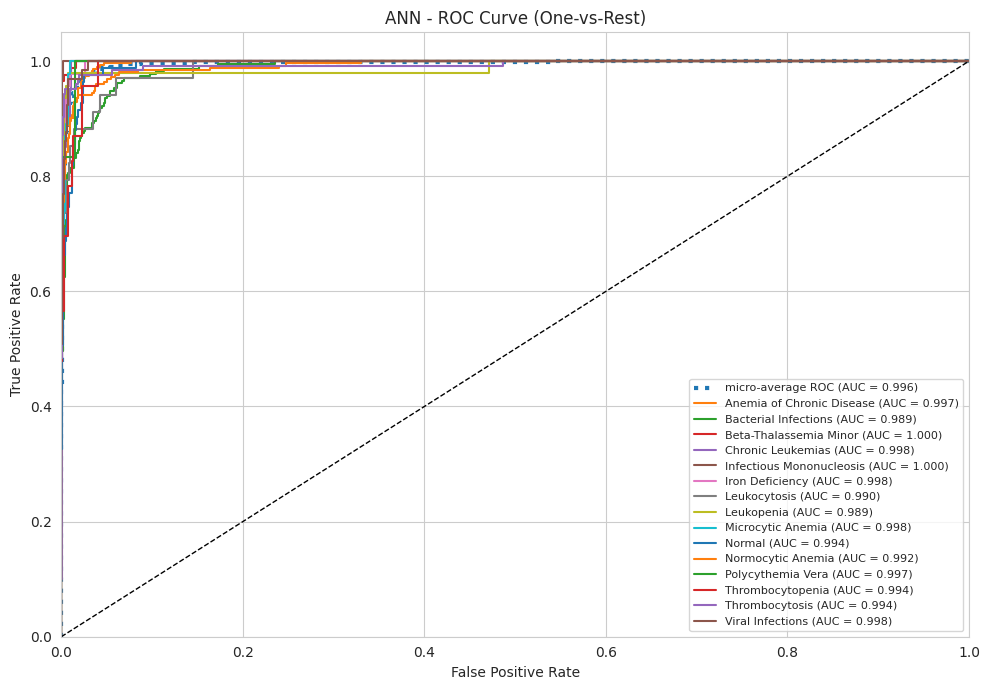

In [ ]:
# --------------------- ANN (tuned) ---------------------
input_dim = X_train_ann.shape[1]

ann_model = models.Sequential([
    layers.Input(shape=(input_dim,)),

    layers.Dense(256, activation="relu",
                 kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.1),

    layers.Dense(128, activation="relu",
                 kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.1),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(num_classes, activation="softmax"),
])

ann_model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
ann_model.summary()

ann_history = ann_model.fit(
    X_train_ann, y_train_cat,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    class_weight=class_weight_dict,
    verbose=1,
)

evaluate_dl_model(ann_model, ann_history,
                  X_test_ann, y_test_cat, y_test, "ANN")


## CNN (1D Convolutional Neural Network)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 16, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 16, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 8, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 8, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,311 (184.81 KB)

 Trainable params: 46,927 (183.31 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.4490 - loss: 1.7823 - val_accuracy: 0.1580 - val_loss: 2.4810
Epoch 2/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6596 - loss: 1.0814 - val_accuracy: 0.2326 - val_loss: 2.8041
Epoch 3/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7385 - loss: 0.8042 - val_accuracy: 0.2431 - val_loss: 2.6171
Epoch 4/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7758 - loss: 0.7026 - val_accuracy: 0.6233 - val_loss: 1.1699
Epoch 5/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7939 - loss: 0.6031 - val_accuracy: 0.8125 - val_loss: 0.5274
Epoch 6/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8078 - loss: 0.5701 - val_accuracy: 0.8793 - val_loss: 0.3535
Epoch 7/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8304 - loss: 0.4996 - val_accuracy: 0.8585 - val_loss: 0.4097
Epoch 8/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8447 - loss: 0.4659 - val_accuracy:

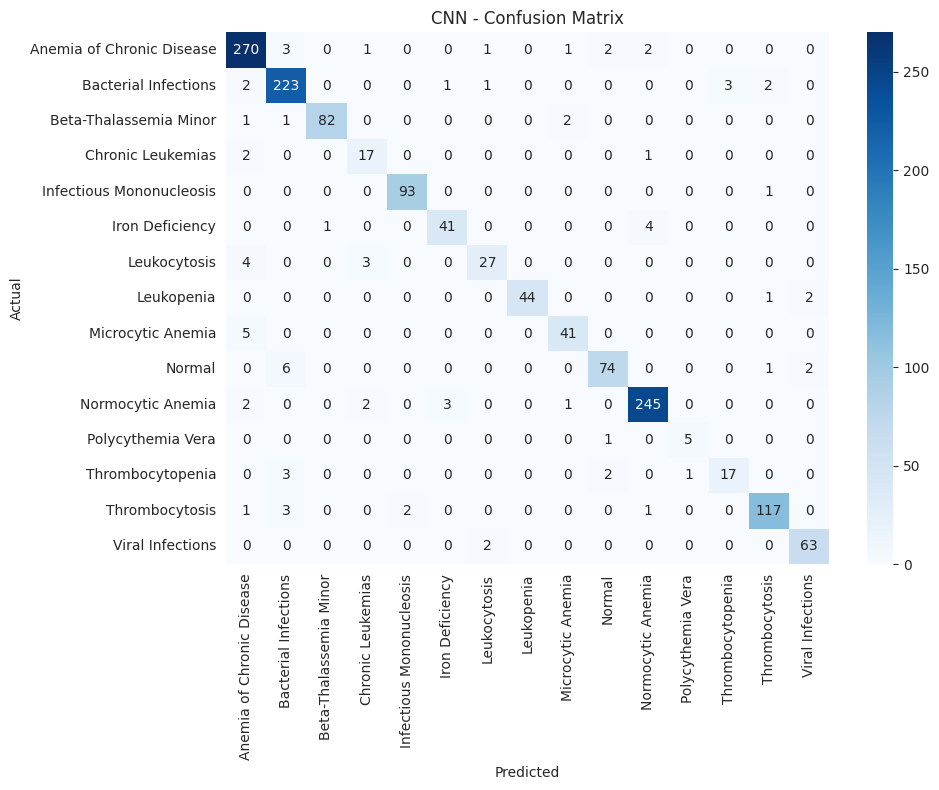

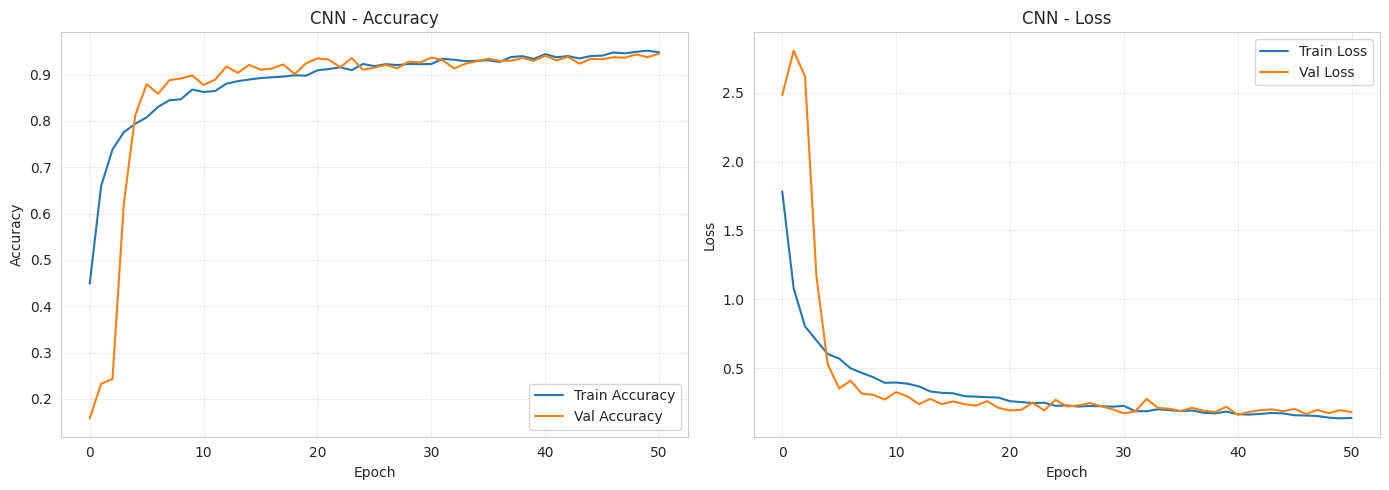

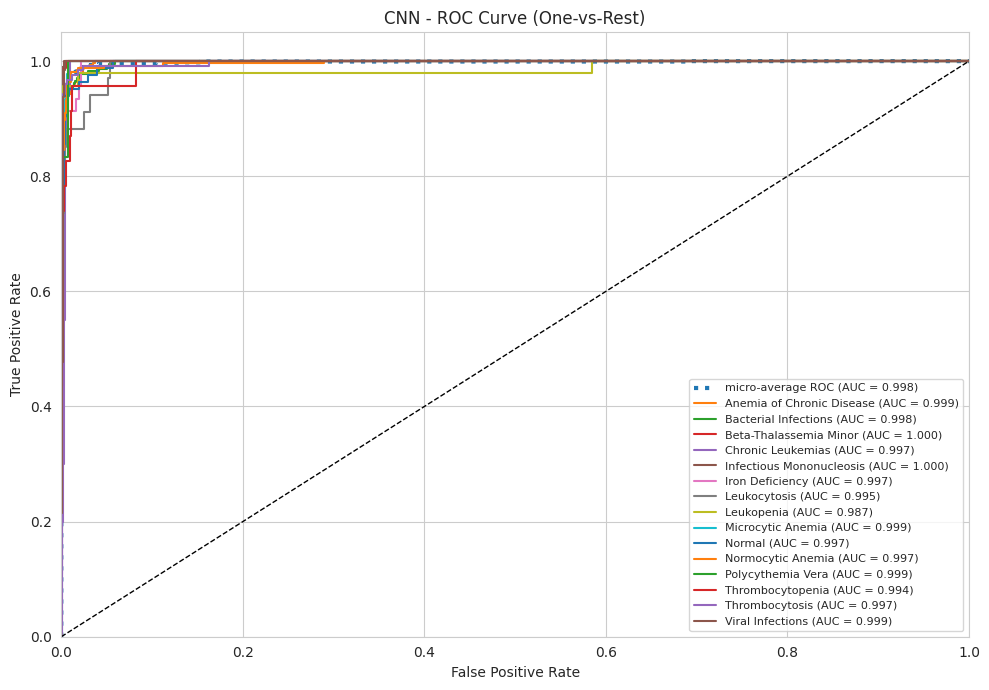

In [ ]:
# --------------------- CNN (1D) ---------------------
seq_len = X_train_seq.shape[1]

cnn_model = models.Sequential([
    layers.Input(shape=(seq_len, 1)),

    layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.Conv1D(filters=64, kernel_size=3, activation='relu', padding='same'),
    layers.MaxPooling1D(pool_size=2),
    layers.Dropout(0.3),

    layers.Conv1D(filters=128, kernel_size=3, activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling1D(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax'),
])

cnn_model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
cnn_model.summary()

cnn_history = cnn_model.fit(
    X_train_seq, y_train_cat,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1,
)

evaluate_dl_model(cnn_model, cnn_history,
                  X_test_seq, y_test_cat, y_test, "CNN")


## RNN (Simple Recurrent Neural Network)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 16, 128)        │        16,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 16, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 16, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,951 (140.43 KB)

 Trainable params: 35,567 (138.93 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.0854 - loss: 3.2153 - val_accuracy: 0.1155 - val_loss: 2.6318 - learning_rate: 5.0000e-04
Epoch 2/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.0977 - loss: 2.9208 - val_accuracy: 0.0885 - val_loss: 2.6711 - learning_rate: 5.0000e-04
Epoch 3/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.1251 - loss: 2.6967 - val_accuracy: 0.1753 - val_loss: 2.4467 - learning_rate: 5.0000e-04
Epoch 4/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.1762 - loss: 2.4416 - val_accuracy: 0.2717 - val_loss: 2.1398 - learning_rate: 5.0000e-04
Epoch 5/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.2166 - loss: 2.2440 - val_accuracy: 0.4062 - val_loss: 1.7844 - learning_rate: 5.0000e-04
Epoch 6/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.2646 - loss: 2.0659 - val_accuracy: 0.3368 - val_loss: 2.0381 - learning_rate: 5.0000e-04
Epoch 7/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - ac

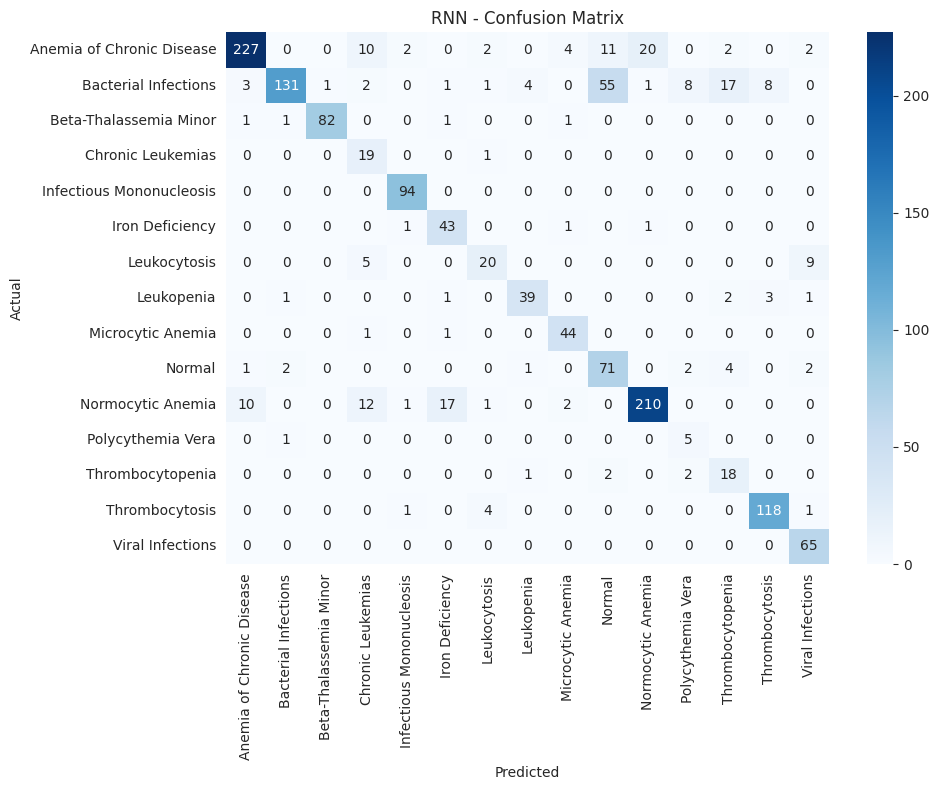

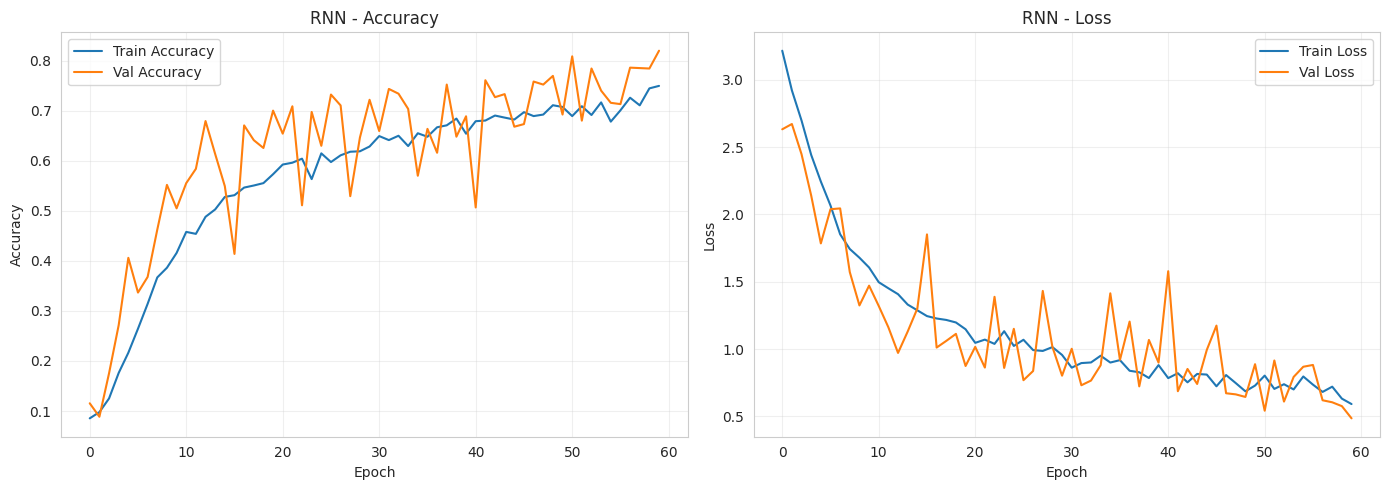

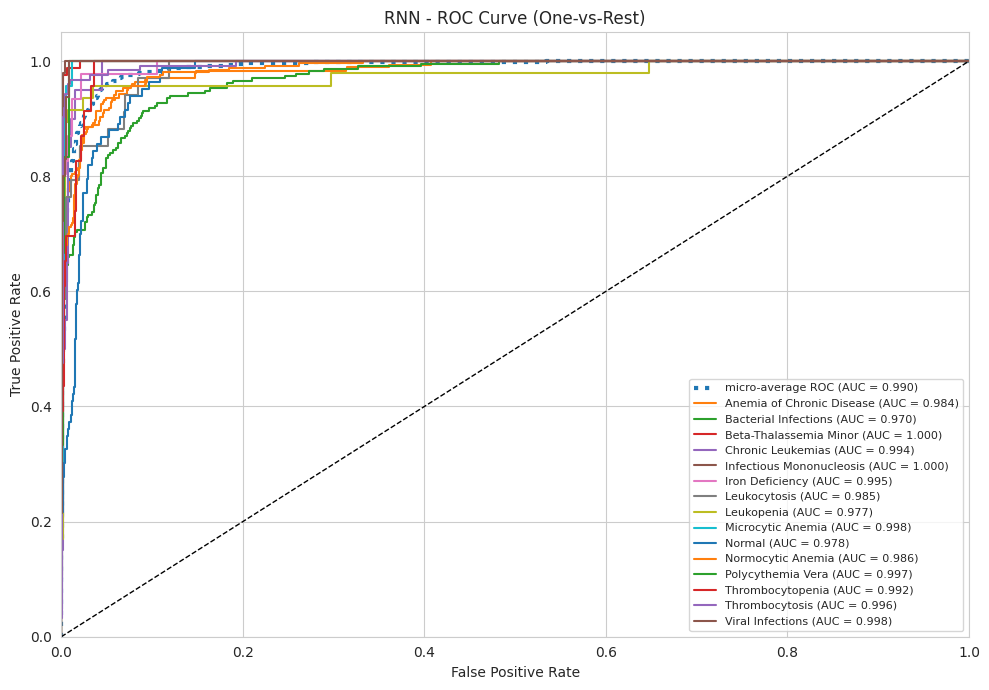

In [ ]:
# --------------------- RNN (tuned) ---------------------
seq_len = X_train_seq.shape[1]

rnn_model = models.Sequential([
    layers.Input(shape=(seq_len, 1)),

    layers.SimpleRNN(128, return_sequences=True, activation="tanh",
                     kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.SimpleRNN(64, return_sequences=True, activation="tanh"),
    layers.Dropout(0.3),

    layers.SimpleRNN(32, activation="tanh"),
    layers.Dropout(0.3),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax"),
])

rnn_model.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
rnn_model.summary()

rnn_history = rnn_model.fit(
    X_train_seq, y_train_cat,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    class_weight=class_weight_dict,
    verbose=1,
)

evaluate_dl_model(rnn_model, rnn_history,
                  X_test_seq, y_test_cat, y_test, "RNN")


## LSTM (Long Short-Term Memory)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16, 128)        │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 16, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 16, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,239 (516.56 KB)

 Trainable params: 131,855 (515.06 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.1034 - loss: 2.9222 - val_accuracy: 0.0816 - val_loss: 2.6998 - learning_rate: 5.0000e-04
Epoch 2/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - accuracy: 0.1483 - loss: 2.5824 - val_accuracy: 0.0660 - val_loss: 2.6692 - learning_rate: 5.0000e-04
Epoch 3/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 77ms/step - accuracy: 0.1727 - loss: 2.4277 - val_accuracy: 0.0781 - val_loss: 2.5208 - learning_rate: 5.0000e-04
Epoch 4/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 18s 62ms/step - accuracy: 0.2048 - loss: 2.3199 - val_accuracy: 0.2005 - val_loss: 2.3197 - learning_rate: 5.0000e-04
Epoch 5/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step - accuracy: 0.2096 - loss: 2.2618 - val_accuracy: 0.1884 - val_loss: 2.2587 - learning_rate: 5.0000e-04
Epoch 6/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.2344 - loss: 2.2046 - val_accuracy: 0.2352 - val_loss: 2.2019 - learning_rate: 5.0000e-04
Epoch 7/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step 

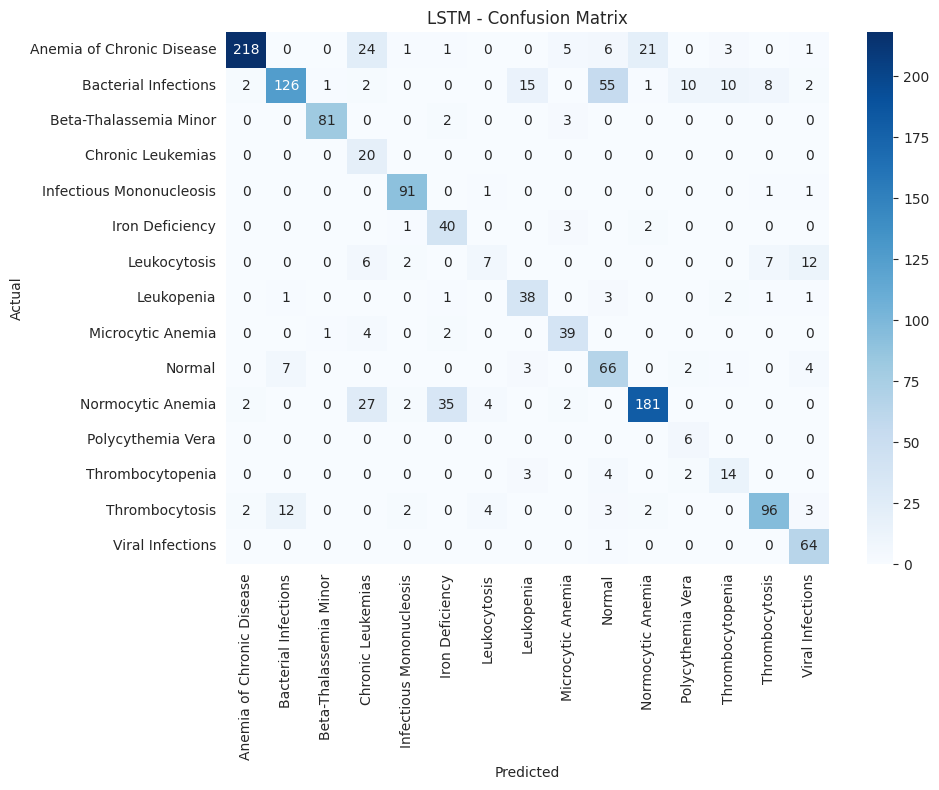

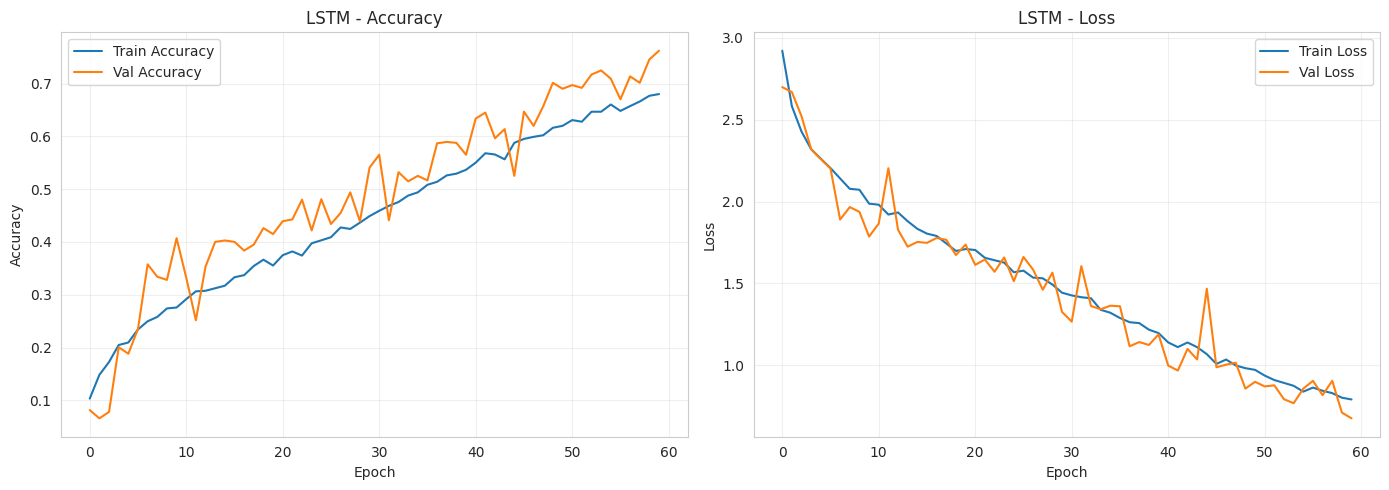

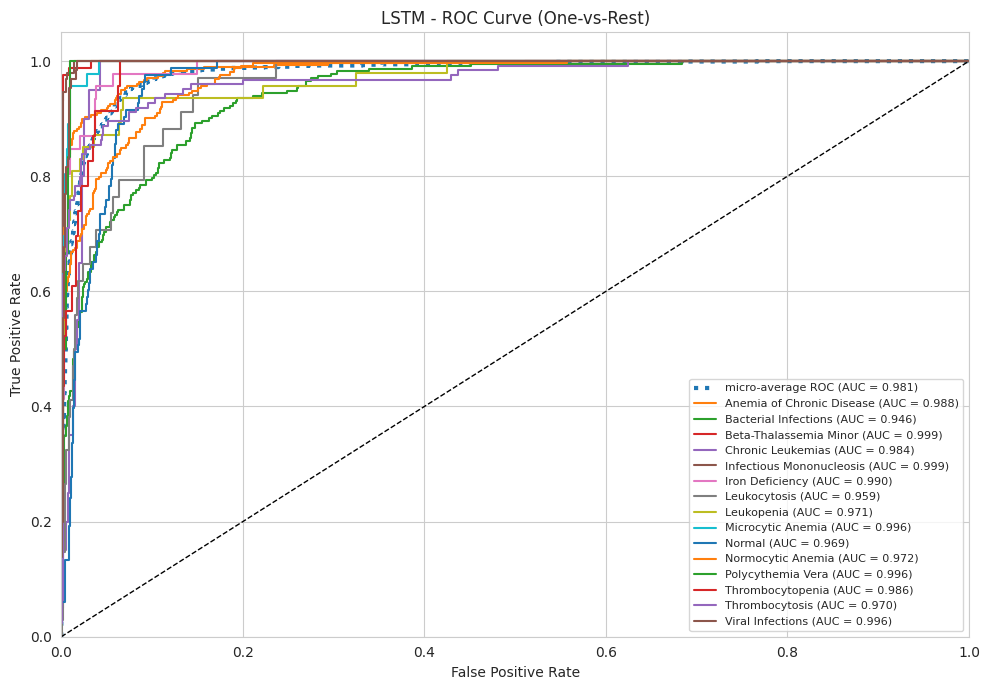

In [ ]:
# --------------------- LSTM (tuned) ---------------------
lstm_model = models.Sequential([
    layers.Input(shape=(seq_len, 1)),

    layers.LSTM(128, return_sequences=True,
                recurrent_dropout=0.2,
                kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.LSTM(64, return_sequences=True, recurrent_dropout=0.2),
    layers.Dropout(0.3),

    layers.LSTM(32),
    layers.Dropout(0.3),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax"),
])

lstm_model.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
lstm_model.summary()

lstm_history = lstm_model.fit(
    X_train_seq, y_train_cat,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    class_weight=class_weight_dict,
    verbose=1,
)

evaluate_dl_model(lstm_model, lstm_history,
                  X_test_seq, y_test_cat, y_test, "LSTM")


## Autoencoder (Self-Supervised Pretraining + Classifier Head)

An **Autoencoder** is a self-supervised deep learning model that learns to compress
the input into a low-dimensional latent representation (the *encoder*) and then
reconstruct the original input from that representation (the *decoder*).

The pipeline used here:

1. **Pretrain** a fully-connected autoencoder on the (Standard-scaled) CBC features
   with an MSE reconstruction loss. The encoder learns a compact, denoised
   representation of the haematology measurements.
2. **Freeze** the encoder and attach a small classification head on top of the
   latent code, then fine-tune end-to-end with cross-entropy.
3. **Evaluate** the resulting classifier with the same unified evaluator used
   for every other deep model, so results are directly comparable.

This gives us a deep model whose features are explicitly optimised to preserve
the structure of the input distribution, which often helps when classes are
imbalanced.


Model: "Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ae_input (InputLayer)           │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 16)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,160 (31.88 KB)

 Trainable params: 7,776 (30.38 KB)

 Non-trainable params: 384 (1.50 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 16)             │         4,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 15)             │           495 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,999 (31.25 KB)

 Trainable params: 7,679 (30.00 KB)

 Non-trainable params: 320 (1.25 KB)

Epoch 1/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.1690 - loss: 2.4768 - val_accuracy: 0.3012 - val_loss: 2.1973 - learning_rate: 5.0000e-04
Epoch 2/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4025 - loss: 1.7039 - val_accuracy: 0.5668 - val_loss: 1.5786 - learning_rate: 5.0000e-04
Epoch 3/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5393 - loss: 1.3054 - val_accuracy: 0.6806 - val_loss: 1.1485 - learning_rate: 5.0000e-04
Epoch 4/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6221 - loss: 1.0853 - val_accuracy: 0.7196 - val_loss: 0.9310 - learning_rate: 5.0000e-04
Epoch 5/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6642 - loss: 0.9379 - val_accuracy: 0.7483 - val_loss: 0.8085 - learning_rate: 5.0000e-04
Epoch 6/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6785 - loss: 0.8626 - val_accuracy: 0.7708 - val_loss: 0.7440 - learning_rate: 5.0000e-04
Epoch 7/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 

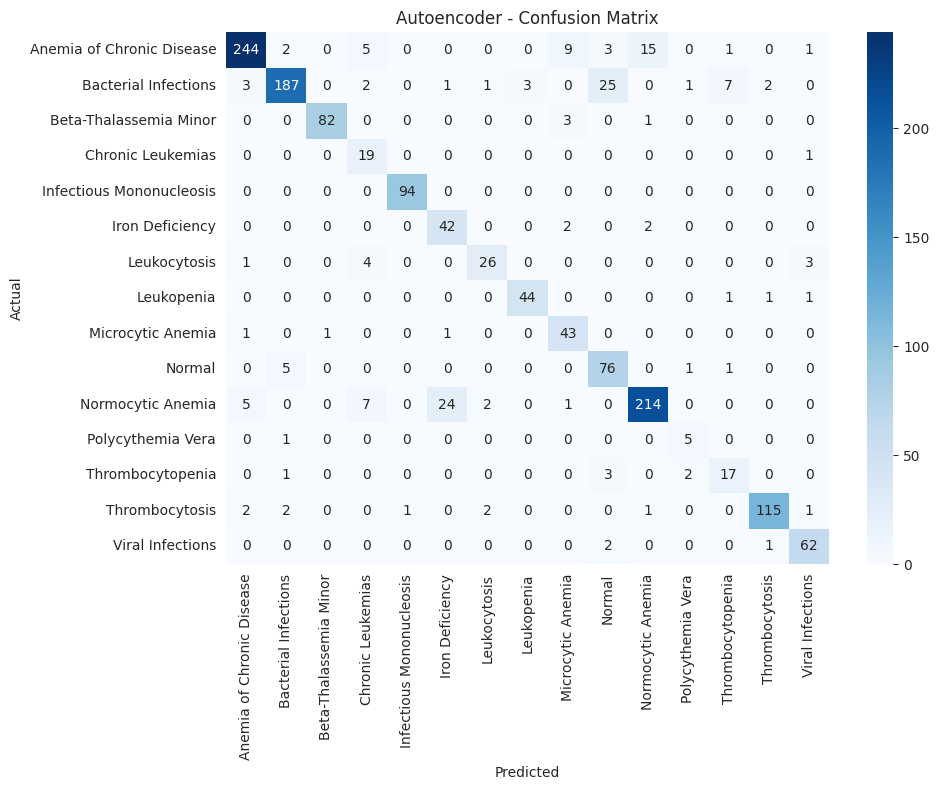

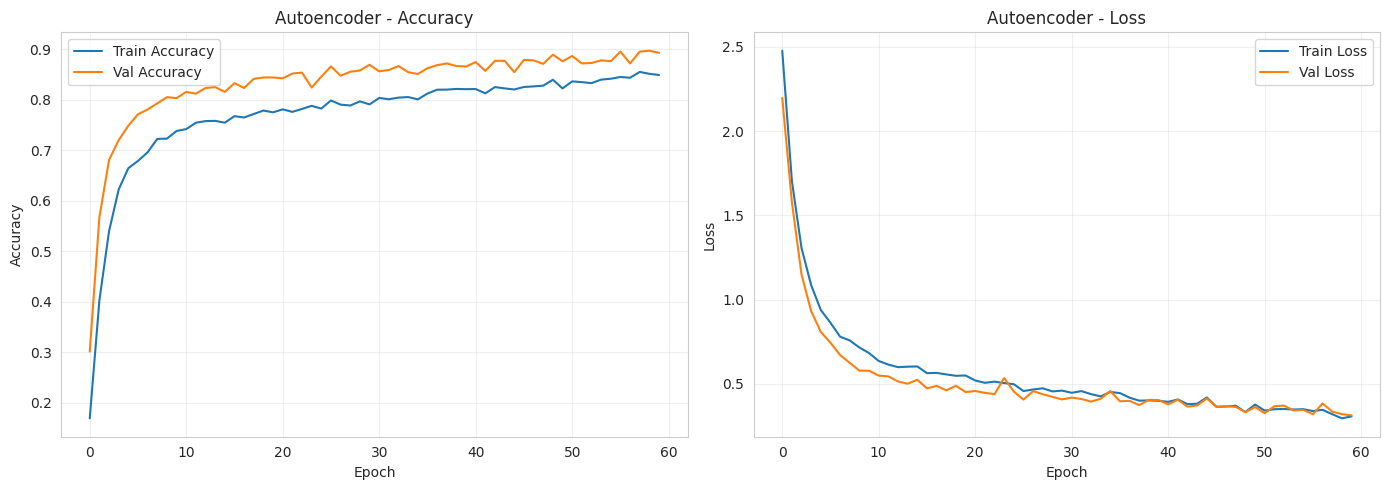

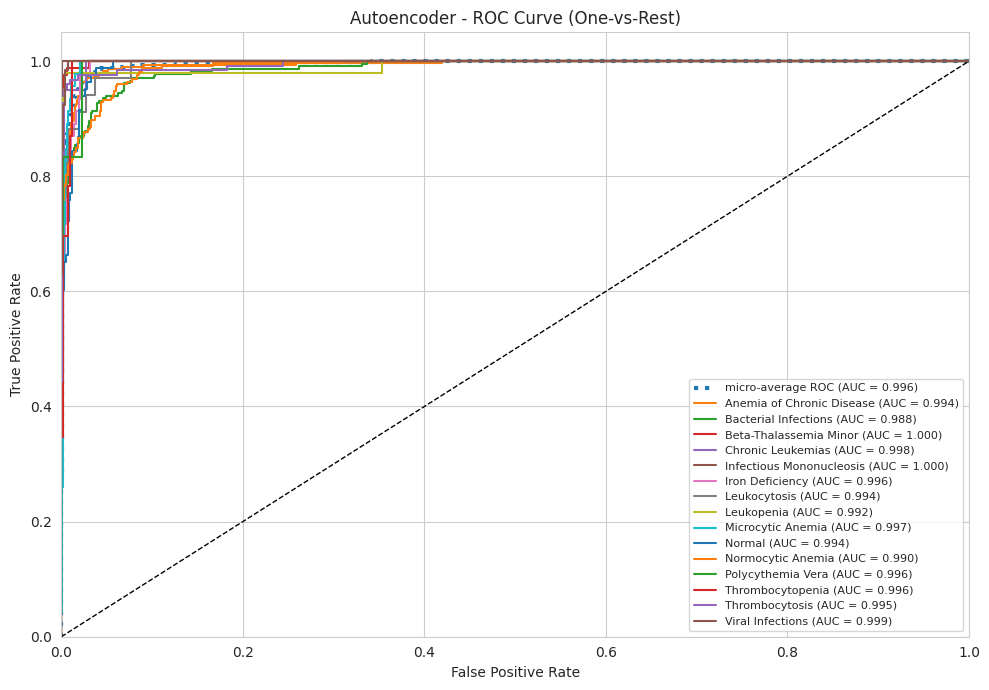

In [18]:
# --------------------- Autoencoder + Classifier ---------------------
# Stage 1: train an autoencoder on the (standard-scaled) flat features
# Stage 2: take the encoder, attach a classifier head, fine-tune end-to-end

input_dim    = X_train_ann.shape[1]
latent_dim   = 16

# ---- Encoder ----
ae_inputs = layers.Input(shape=(input_dim,), name="ae_input")
x = layers.Dense(64, activation="relu",
                 kernel_regularizer=regularizers.l2(1e-4))(ae_inputs)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.1)(x)
x = layers.Dense(32, activation="relu",
                 kernel_regularizer=regularizers.l2(1e-4))(x)
x = layers.BatchNormalization()(x)
latent = layers.Dense(latent_dim, activation="relu", name="latent")(x)

# ---- Decoder ----
d = layers.Dense(32, activation="relu")(latent)
d = layers.BatchNormalization()(d)
d = layers.Dense(64, activation="relu")(d)
d = layers.BatchNormalization()(d)
decoded = layers.Dense(input_dim, activation="linear", name="reconstruction")(d)

autoencoder = models.Model(ae_inputs, decoded, name="Autoencoder")
autoencoder.compile(optimizer=Adam(learning_rate=1e-3), loss="mse")
autoencoder.summary()

# ----- Pretrain: reconstruct the (standard-scaled) inputs -----
ae_history = autoencoder.fit(
    X_train_ann, X_train_ann,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    verbose=1,
)

# ----- Build classifier on top of the encoder -----
encoder = models.Model(ae_inputs, latent, name="Encoder")

clf_inputs   = layers.Input(shape=(input_dim,))
encoded_feat = encoder(clf_inputs)
h = layers.Dense(64, activation="relu",
                 kernel_regularizer=regularizers.l2(1e-4))(encoded_feat)
h = layers.BatchNormalization()(h)
h = layers.Dropout(0.1)(h)
h = layers.Dense(32, activation="relu")(h)
h = layers.Dropout(0.1)(h)
clf_outputs = layers.Dense(num_classes, activation="softmax")(h)

ae_classifier = models.Model(clf_inputs, clf_outputs, name="AE_Classifier")
ae_classifier.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
ae_classifier.summary()

ae_clf_history = ae_classifier.fit(
    X_train_ann, y_train_cat,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    class_weight=class_weight_dict,
    verbose=1,
)

evaluate_dl_model(ae_classifier, ae_clf_history,
                  X_test_ann, y_test_cat, y_test, "Autoencoder")


# Hybrid Deep Learning Models

Combine multiple sequence-learning paradigms for richer feature representations:
- **CNN + BiLSTM** — local feature extraction via 1D convolutions, then bidirectional long-range modelling.
- **RNN + BiLSTM** — SimpleRNN encoder followed by a BiLSTM that mitigates vanishing gradients and adds bidirectional context.
- **CNN + RNN + BiLSTM** — three-stage hybrid combining convolutional feature extraction, RNN sequence encoding, and bidirectional LSTM refinement.


## CNN + BiLSTM

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_9 (Conv1D)               │ (None, 16, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 16, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_10 (Conv1D)              │ (None, 16, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_11 (Conv1D)              │ (None, 8, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 8, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ (None, 8, 128)         │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_38 (Dropout)            │ (None, 8, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_6 (Bidirectional) │ (None, 64)             │        41,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 183,503 (716.81 KB)

 Trainable params: 182,991 (714.81 KB)

 Non-trainable params: 512 (2.00 KB)

Epoch 1/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 28s 53ms/step - accuracy: 0.3614 - loss: 1.8377 - val_accuracy: 0.0339 - val_loss: 2.6421 - learning_rate: 5.0000e-04
Epoch 2/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.5602 - loss: 1.1880 - val_accuracy: 0.0365 - val_loss: 2.7999 - learning_rate: 5.0000e-04
Epoch 3/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.6438 - loss: 0.9260 - val_accuracy: 0.1111 - val_loss: 2.8538 - learning_rate: 5.0000e-04
Epoch 4/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.6942 - loss: 0.7813 - val_accuracy: 0.5365 - val_loss: 1.3309 - learning_rate: 5.0000e-04
Epoch 5/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.7144 - loss: 0.7325 - val_accuracy: 0.7908 - val_loss: 0.6110 - learning_rate: 5.0000e-04
Epoch 6/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.7376 - loss: 0.6734 - val_accuracy: 0.7995 - val_loss: 0.5733 - learning_rate: 5.0000e-04
Epoch 7/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - a

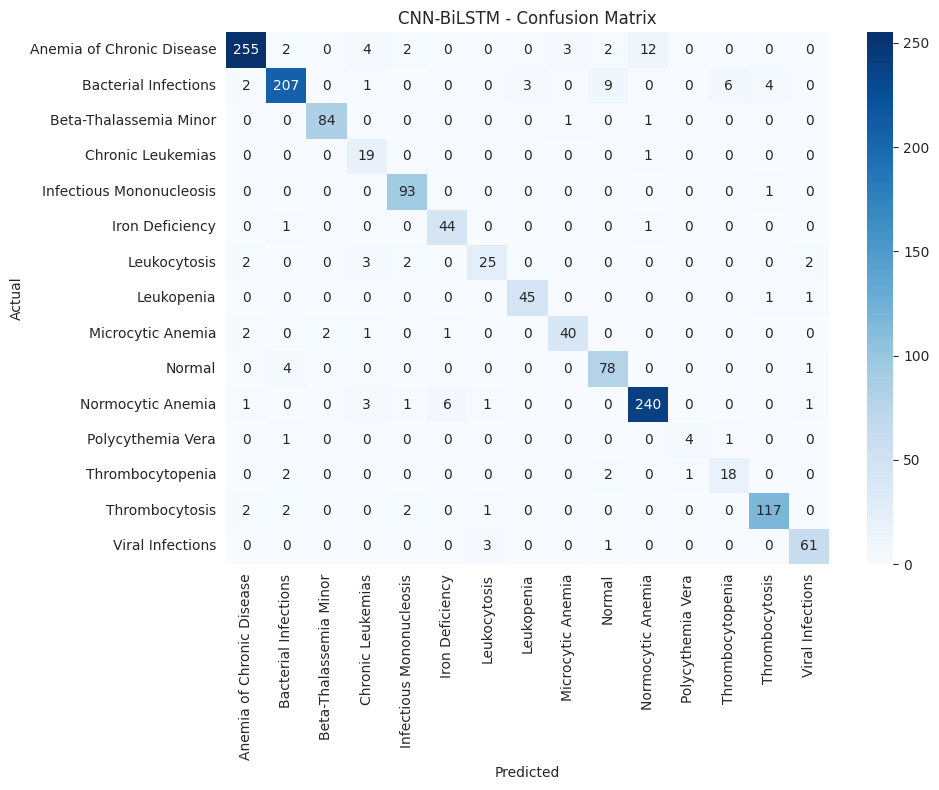

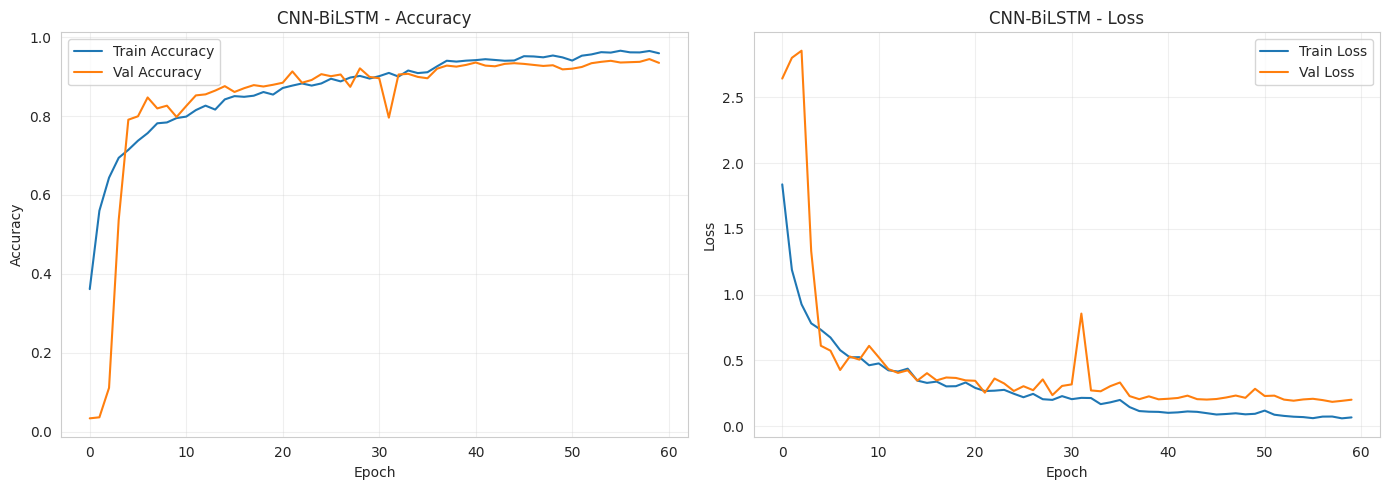

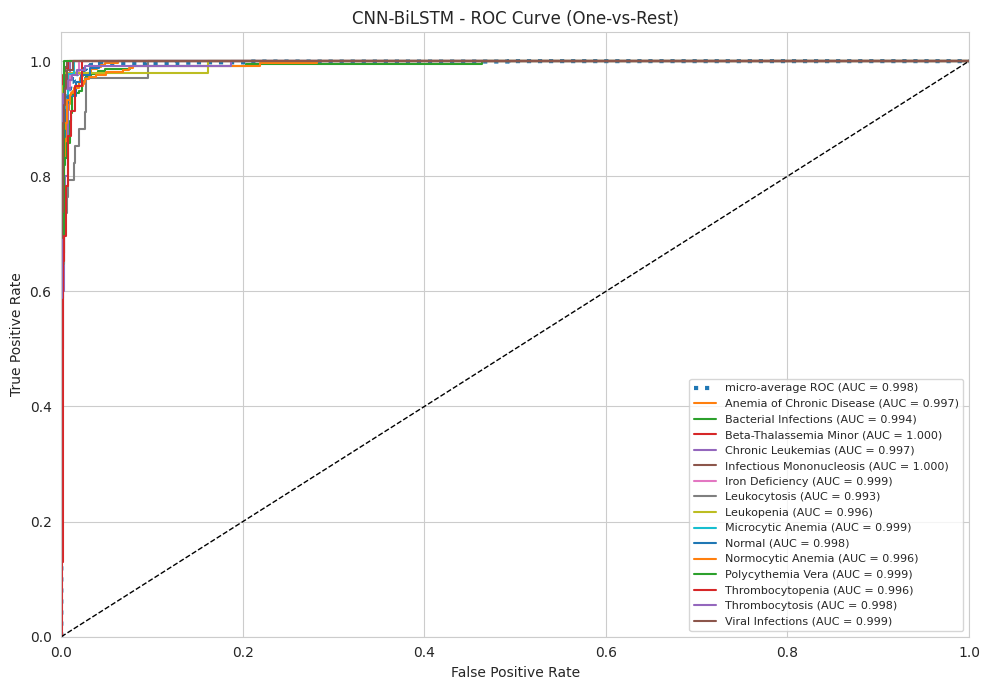

In [ ]:
# --------------------- CNN-BiLSTM Hybrid ---------------------
cnn_bilstm_model = models.Sequential([
    layers.Input(shape=(seq_len, 1)),

    # CNN feature extractor
    layers.Conv1D(64, kernel_size=3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.Conv1D(64, kernel_size=3, activation="relu", padding="same"),
    layers.MaxPooling1D(pool_size=2),
    layers.Dropout(0.1),

    layers.Conv1D(128, kernel_size=3, activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.Dropout(0.1),

    # Bidirectional LSTM on top
    layers.Bidirectional(layers.LSTM(64, return_sequences=True,
                                     recurrent_dropout=0.2)),
    layers.Dropout(0.1),
    layers.Bidirectional(layers.LSTM(32)),
    layers.Dropout(0.1),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(num_classes, activation="softmax"),
])

cnn_bilstm_model.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
cnn_bilstm_model.summary()

cnn_bilstm_history = cnn_bilstm_model.fit(
    X_train_seq, y_train_cat,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    class_weight=class_weight_dict,
    verbose=1,
)

evaluate_dl_model(cnn_bilstm_model, cnn_bilstm_history,
                  X_test_seq, y_test_cat, y_test, "CNN-BiLSTM")


## CNN + Autoencoder

A hybrid that fuses the **local pattern-extraction** strength of a 1D CNN
with the **self-supervised representation learning** of an autoencoder:

1. **1D CNN encoder** convolves over the CBC feature sequence and projects it
   into a compact latent code.
2. **1D CNN decoder** (transposed convolutions) reconstructs the original
   sequence from that latent code, trained with MSE.
3. **Classifier head** is attached to the latent code and fine-tuned end-to-end
   on the diagnosis labels with cross-entropy.

Because the convolutional encoder learns features that are good both for
**reconstruction** and for **classification**, the resulting representation
is robust and structured — which makes it a strong candidate for
post-hoc explainability in the next section.


Model: "CNN_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cae_input (InputLayer)          │ (None, 16, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 16, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 16, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 16, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 8, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 8, 128)         │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 8, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 4, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 4, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cae_latent (Dense)              │ (None, 32)             │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 512)            │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 4, 128)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_2              │ (None, 8, 128)         │        49,280 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 8, 128)         │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_3              │ (None, 16, 64)         │        24,640 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 16, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cae_reconstruction (Conv1D)     │ (None, 16, 1)          │           193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 146,273 (571.38 KB)

 Trainable params: 145,505 (568.38 KB)

 Non-trainable params: 768 (3.00 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 16, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CNN_Encoder (Functional)        │ (None, 32)             │        54,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 15)             │           495 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59,439 (232.18 KB)

 Trainable params: 58,927 (230.18 KB)

 Non-trainable params: 512 (2.00 KB)

Epoch 1/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.1705 - loss: 2.5433 - val_accuracy: 0.4427 - val_loss: 1.9041 - learning_rate: 5.0000e-04
Epoch 2/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3899 - loss: 1.7858 - val_accuracy: 0.6285 - val_loss: 1.3763 - learning_rate: 5.0000e-04
Epoch 3/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5176 - loss: 1.4059 - val_accuracy: 0.7205 - val_loss: 1.0365 - learning_rate: 5.0000e-04
Epoch 4/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5964 - loss: 1.1547 - val_accuracy: 0.7188 - val_loss: 0.9489 - learning_rate: 5.0000e-04
Epoch 5/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.6347 - loss: 1.0107 - val_accuracy: 0.7821 - val_loss: 0.7421 - learning_rate: 5.0000e-04
Epoch 6/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.6735 - loss: 0.9181 - val_accuracy: 0.8064 - val_loss: 0.6610 - learning_rate: 5.0000e-04
Epoch 7/60
144/144 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - acc

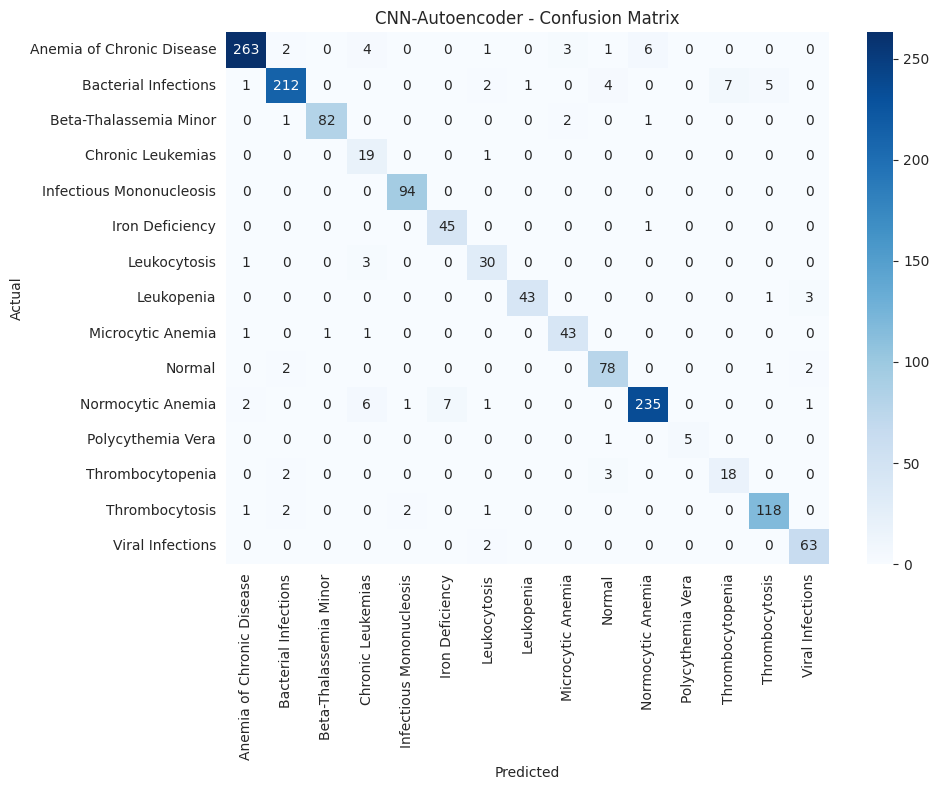

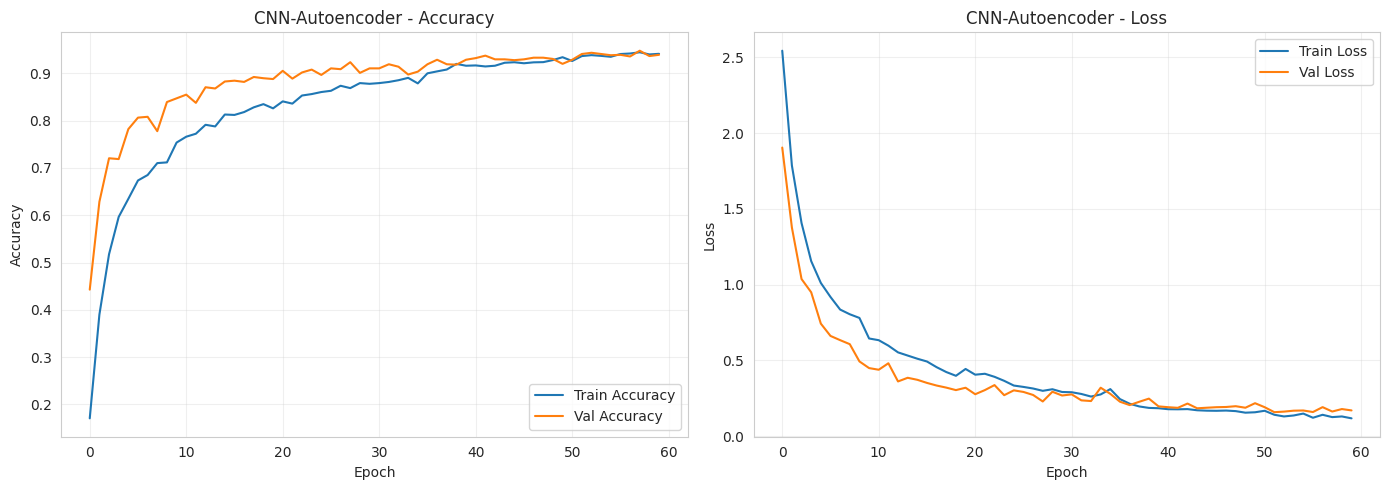

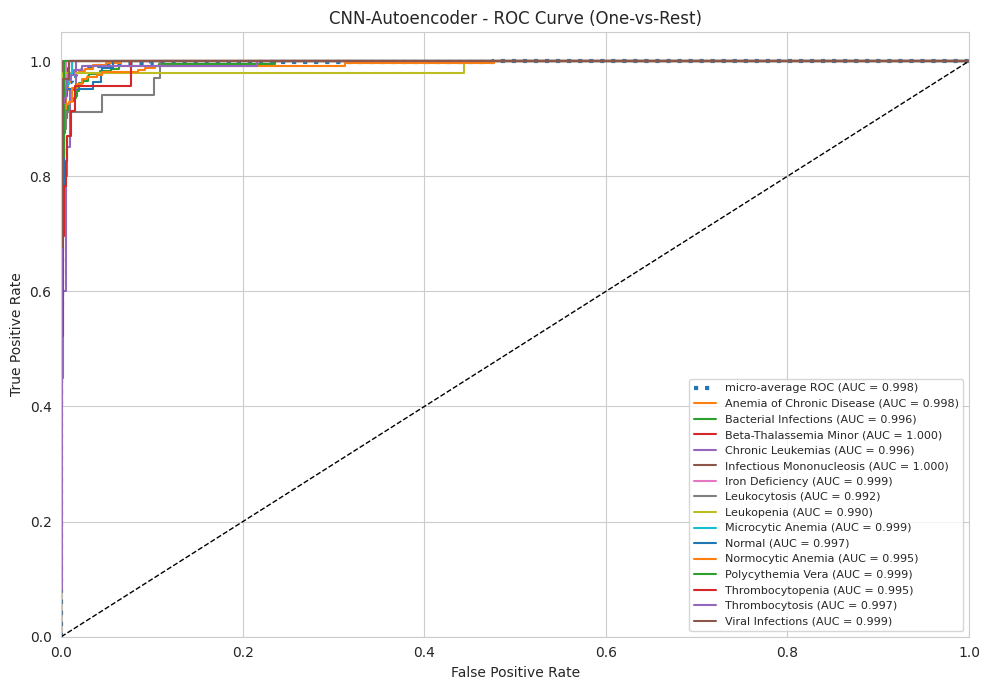

In [21]:
# --------------------- CNN + Autoencoder Hybrid ---------------------
# Stage 1: 1D convolutional autoencoder on the (MinMax-scaled) sequence input
# Stage 2: classifier head on the convolutional latent code

seq_len     = X_train_seq.shape[1]
latent_dim  = 32

# ---- Convolutional Encoder ----
cae_inputs = layers.Input(shape=(seq_len, 1), name="cae_input")

e = layers.Conv1D(64, kernel_size=3, activation="relu", padding="same")(cae_inputs)
e = layers.BatchNormalization()(e)
e = layers.Conv1D(64, kernel_size=3, activation="relu", padding="same")(e)
e = layers.MaxPooling1D(pool_size=2, padding="same")(e)
e = layers.Dropout(0.1)(e)

e = layers.Conv1D(128, kernel_size=3, activation="relu", padding="same")(e)
e = layers.BatchNormalization()(e)
e = layers.MaxPooling1D(pool_size=2, padding="same")(e)
e = layers.Dropout(0.1)(e)

# Flatten -> dense latent code
shape_before_flatten = e.shape[1:]                      # (steps, channels)
flat = layers.Flatten()(e)
cae_latent = layers.Dense(latent_dim, activation="relu",
                          name="cae_latent")(flat)

# ---- Convolutional Decoder ----
d = layers.Dense(int(np.prod(shape_before_flatten)),
                 activation="relu")(cae_latent)
d = layers.Reshape(shape_before_flatten)(d)

d = layers.Conv1DTranspose(128, kernel_size=3, strides=2,
                           activation="relu", padding="same")(d)
d = layers.BatchNormalization()(d)
d = layers.Conv1DTranspose(64, kernel_size=3, strides=2,
                           activation="relu", padding="same")(d)
d = layers.BatchNormalization()(d)
d_out = layers.Conv1D(1, kernel_size=3, activation="linear",
                      padding="same", name="cae_reconstruction")(d)

# Make sure decoded output length matches input seq_len (crop if needed)
if d_out.shape[1] != seq_len:
    d_out = layers.Cropping1D((0, d_out.shape[1] - seq_len))(d_out)

cnn_autoencoder = models.Model(cae_inputs, d_out, name="CNN_Autoencoder")
cnn_autoencoder.compile(optimizer=Adam(learning_rate=1e-3), loss="mse")
cnn_autoencoder.summary()

# ----- Pretrain: reconstruct the (MinMax-scaled) sequence input -----
cae_history = cnn_autoencoder.fit(
    X_train_seq, X_train_seq,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    verbose=1,
)

# ----- Build classifier on top of the convolutional latent -----
cnn_encoder = models.Model(cae_inputs, cae_latent, name="CNN_Encoder")

cae_clf_inputs   = layers.Input(shape=(seq_len, 1))
cae_encoded_feat = cnn_encoder(cae_clf_inputs)
h = layers.Dense(64, activation="relu",
                 kernel_regularizer=regularizers.l2(1e-4))(cae_encoded_feat)
h = layers.BatchNormalization()(h)
h = layers.Dropout(0.3)(h)
h = layers.Dense(32, activation="relu")(h)
h = layers.Dropout(0.2)(h)
cae_clf_outputs = layers.Dense(num_classes, activation="softmax")(h)

cnn_autoencoder_classifier = models.Model(
    cae_clf_inputs, cae_clf_outputs, name="CNN_AE_Classifier"
)
cnn_autoencoder_classifier.compile(
    optimizer=Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
cnn_autoencoder_classifier.summary()

cae_clf_history = cnn_autoencoder_classifier.fit(
    X_train_seq, y_train_cat,
    validation_split=VAL_SPLIT,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=make_callbacks(),
    class_weight=class_weight_dict,
    verbose=1,
)

evaluate_dl_model(cnn_autoencoder_classifier, cae_clf_history,
                  X_test_seq, y_test_cat, y_test, "CNN-Autoencoder")


# Explainable AI

We now interpret the predictions of the **CNN + Autoencoder** hybrid deep learning model
using four complementary approaches:

1. **Permutation Importance** — model-agnostic global feature ranking based on the drop in test accuracy when each feature is randomly shuffled.
2. **Gradient-based Importance** — uses input gradients (saliency) to measure how sensitive the model's output is to each input feature.
3. **SHAP (SHapley Additive exPlanations)** — game-theoretic feature attributions, both globally (mean |SHAP| across the test set) and locally (waterfall plot for a single patient).
4. **LIME (Local Interpretable Model-agnostic Explanations)** — fits a simple surrogate model around a single prediction to explain it in human-readable terms.

Since the deep model takes input shaped `(samples, seq_len, 1)` while SHAP/LIME work on
flat tabular input, we wrap the model in a small adapter function `predict_flat(...)`
that reshapes input internally.


In [22]:

!pip install -q shap lime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



dl_model       = cnn_autoencoder_classifier
feature_names  = X.columns.tolist()
class_names    = le.classes_.tolist()
n_features     = len(feature_names)

# Background / test sets in flat MinMax space (what SHAP & LIME need)
X_train_flat = X_train_mm                  # already MinMax-scaled
X_test_flat  = X_test_mm

def predict_flat(x_flat):
    """Take 2D MinMax-scaled input, reshape to (n, seq_len, 1), return class probs."""
    x_flat = np.asarray(x_flat, dtype=np.float32)
    if x_flat.ndim == 1:
        x_flat = x_flat.reshape(1, -1)
    x_seq = x_flat.reshape(x_flat.shape[0], n_features, 1)
    return dl_model.predict(x_seq, verbose=0)

# Quick sanity check
probs = predict_flat(X_test_flat[:3])
print("Wrapper output shape:", probs.shape)
print("Row sums (should be ~1):", probs.sum(axis=1).round(4))
print("Number of features    :", n_features)
print("Number of classes     :", len(class_names))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 6.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Wrapper output shape: (3, 15)
Row sums (should be ~1): [1. 1. 1.]
Number of features    : 16
Number of classes     : 15


## Permutation Importance (CNN-Autoencoder)



Baseline test accuracy: 0.9368
  [ 1/16] Gender                               drop = +0.0805 ± 0.0040
  [ 2/16] Age                                  drop = +0.0100 ± 0.0016
  [ 3/16] Hb                                   drop = +0.1657 ± 0.0057
  [ 4/16] RBC                                  drop = +0.1088 ± 0.0052
  [ 5/16] WBC                                  drop = +0.1643 ± 0.0085
  [ 6/16] PLATELETS                            drop = +0.1305 ± 0.0054
  [ 7/16] LYMP                                 drop = +0.1504 ± 0.0060
  [ 8/16] MONO                                 drop = +0.0866 ± 0.0029
  [ 9/16] HCT                                  drop = +0.0354 ± 0.0015
  [10/16] MCV                                  drop = +0.0727 ± 0.0075
  [11/16] MCH                                  drop = +0.0567 ± 0.0053
  [12/16] MCHC                                 drop = +0.0585 ± 0.0038
  [13/16] RDW                                  drop = +0.1912 ± 0.0093
  [14/16] PDW                                 

,Feature,Importance,Std
12,RDW,0.1912,0.0093
2,Hb,0.1657,0.0057
4,WBC,0.1643,0.0085
6,LYMP,0.1504,0.0060
5,PLATELETS,0.1305,0.0054
3,RBC,0.1088,0.0052
7,MONO,0.0866,0.0029
0,Gender,0.0805,0.0040
9,MCV,0.0727,0.0075
11,MCHC,0.0585,0.0038


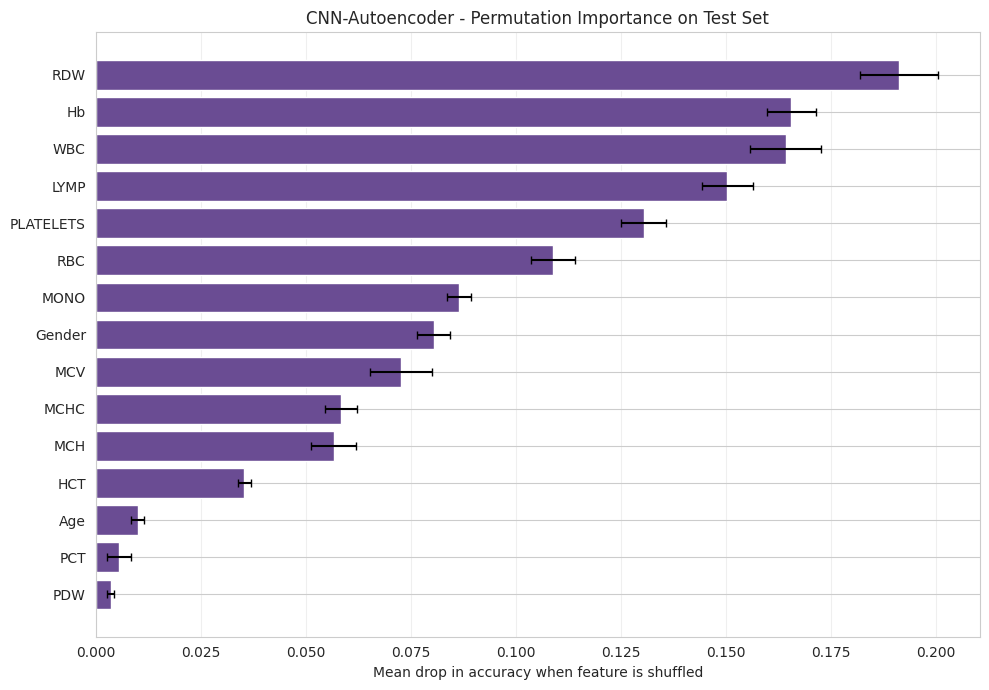

In [23]:
# ---------------------------------------------------------
# Permutation Importance for the CNN-Autoencoder model
# ---------------------------------------------------------
from sklearn.metrics import accuracy_score

rng = np.random.RandomState(42)
n_repeats = 5      # increase for tighter error bars (slower)

# Baseline accuracy
baseline_preds = np.argmax(predict_flat(X_test_flat), axis=1)
baseline_acc   = accuracy_score(y_test, baseline_preds)
print(f"Baseline test accuracy: {baseline_acc:.4f}")

importances_mean = np.zeros(n_features)
importances_std  = np.zeros(n_features)

for j in range(n_features):
    drops = []
    for _ in range(n_repeats):
        X_perm = X_test_flat.copy()
        rng.shuffle(X_perm[:, j])           # shuffle column j in place
        preds = np.argmax(predict_flat(X_perm), axis=1)
        drops.append(baseline_acc - accuracy_score(y_test, preds))
    importances_mean[j] = np.mean(drops)
    importances_std[j]  = np.std(drops)
    print(f"  [{j+1:2d}/{n_features}] {feature_names[j]:35s}  "
          f"drop = {importances_mean[j]:+.4f} ± {importances_std[j]:.4f}")

perm_df = pd.DataFrame({
    "Feature":    feature_names,
    "Importance": importances_mean,
    "Std":        importances_std
}).sort_values("Importance", ascending=False)

print("\nTop 15 features by permutation importance:")
display(perm_df.head(15).round(4))

# Bar plot
top_perm = perm_df.head(15).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top_perm["Feature"], top_perm["Importance"],
         xerr=top_perm["Std"], color="#6A4C93", ecolor="black", capsize=3)
plt.title("CNN-Autoencoder - Permutation Importance on Test Set")
plt.xlabel("Mean drop in accuracy when feature is shuffled")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## Gradient-based Feature Importance

Uses **saliency** — the absolute value of the gradient of the predicted class score with
respect to each input feature, averaged over the test set. Larger values mean the
network's output is more sensitive to that feature, which is a fast proxy for
global importance for a deep model.


Top 15 features by gradient-based saliency:


,Feature,Importance
4,WBC,5.8348
12,RDW,1.6182
2,Hb,1.1882
5,PLATELETS,0.8847
8,HCT,0.7836
0,Gender,0.7098
3,RBC,0.7061
10,MCH,0.5955
11,MCHC,0.5940
6,LYMP,0.5776


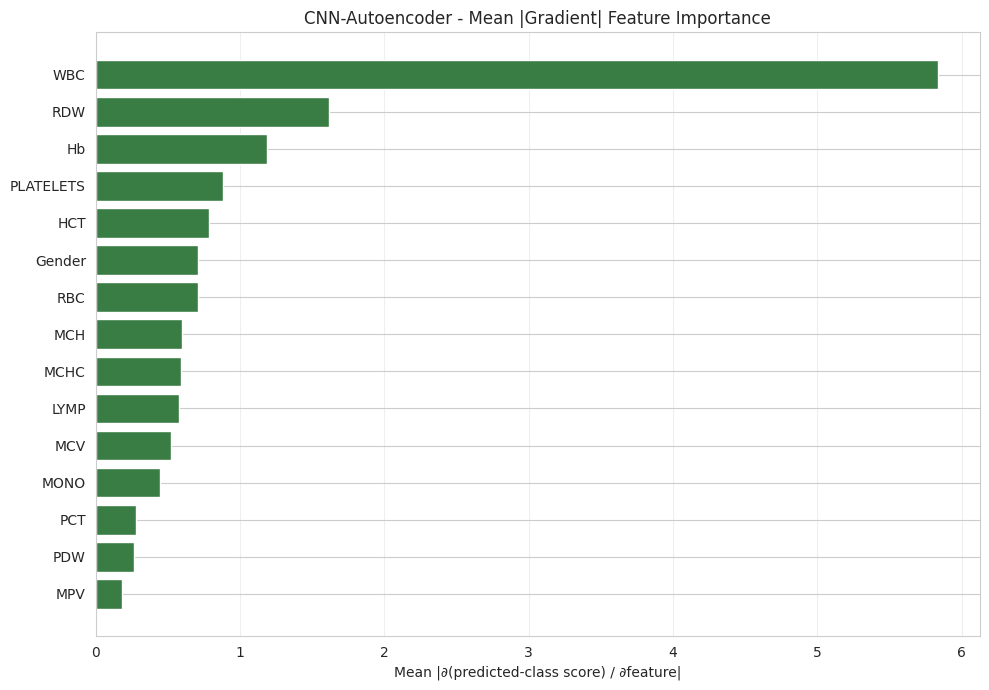

In [24]:
# ---------------------------------------------------------
# Gradient-based (saliency) importance for the deep model
# ---------------------------------------------------------
import tensorflow as tf

X_test_tensor = tf.convert_to_tensor(
    X_test_flat.reshape(-1, n_features, 1).astype(np.float32)
)

with tf.GradientTape() as tape:
    tape.watch(X_test_tensor)
    preds = dl_model(X_test_tensor, training=False)
    # Score for the predicted class of each sample
    pred_idx   = tf.argmax(preds, axis=1)
    pred_score = tf.gather(preds, pred_idx, axis=1, batch_dims=1)

grads = tape.gradient(pred_score, X_test_tensor)        # (n, n_features, 1)
grads = tf.squeeze(grads, axis=-1).numpy()              # (n, n_features)

# Mean absolute gradient per feature -> global importance
grad_importance = np.mean(np.abs(grads), axis=0)

grad_df = pd.DataFrame({
    "Feature":    feature_names,
    "Importance": grad_importance,
}).sort_values("Importance", ascending=False)

print("Top 15 features by gradient-based saliency:")
display(grad_df.head(15).round(4))

top_grad = grad_df.head(15).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top_grad["Feature"], top_grad["Importance"], color="#3A7D44")
plt.title("CNN-Autoencoder - Mean |Gradient| Feature Importance")
plt.xlabel("Mean |∂(predicted-class score) / ∂feature|")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## SHAP (SHapley Additive exPlanations) on CNN-Autoencoder

For deep learning models we cannot use `TreeExplainer`. Instead we use SHAP's
`KernelExplainer` with a small background sample (it's model-agnostic and treats
the network as a black box through `predict_flat`). For larger background sizes
this can be slow, so we use a sampled background and a small subset of the test
set for the global plots.


In [25]:
# =========================================================
# SHAP - Global Explanations for CNN-Autoencoder
# =========================================================
import shap

# KernelExplainer is slow; keep background and test subset small.
BG_SIZE   = 50      # background sample size (used as the "expected value" reference)
TEST_SIZE = 50      # number of test samples to explain for global plots

rng = np.random.RandomState(42)
bg_idx   = rng.choice(X_train_flat.shape[0], size=min(BG_SIZE,   X_train_flat.shape[0]), replace=False)
test_idx = rng.choice(X_test_flat.shape[0],  size=min(TEST_SIZE, X_test_flat.shape[0]),  replace=False)

X_bg     = X_train_flat[bg_idx]
X_sample = X_test_flat[test_idx]

# Build a KernelExplainer over the wrapped predict function
print("Building SHAP KernelExplainer (this may take a couple of minutes)...")
explainer_dl = shap.KernelExplainer(predict_flat, X_bg)

# Compute SHAP values on the sampled test set
# Returns: list of length n_classes, each (n_samples, n_features)  -- old SHAP
#       OR a single ndarray of shape (n_samples, n_features, n_classes) -- newer SHAP
shap_values_dl = explainer_dl.shap_values(X_sample, nsamples=100)

shap_arr = np.array(shap_values_dl)
print("Raw SHAP values shape:", shap_arr.shape)

# Normalise to (n_classes, n_samples, n_features)
if shap_arr.ndim == 3 and shap_arr.shape[0] == X_sample.shape[0]:
    # (n_samples, n_features, n_classes) -> transpose
    shap_arr = np.transpose(shap_arr, (2, 0, 1))

print("Normalised SHAP shape (n_classes, n_samples, n_features):", shap_arr.shape)


Building SHAP KernelExplainer (this may take a couple of minutes)...


  0%|          | 0/50 [00:00<?, ?it/s]

Raw SHAP values shape: (50, 16, 15)
Normalised SHAP shape (n_classes, n_samples, n_features): (15, 50, 16)


Top 15 features by mean |SHAP| value:


,Feature,MeanAbsSHAP
12,RDW,0.0270
2,Hb,0.0264
6,LYMP,0.0250
4,WBC,0.0208
3,RBC,0.0191
5,PLATELETS,0.0180
0,Gender,0.0160
10,MCH,0.0134
7,MONO,0.0132
9,MCV,0.0130


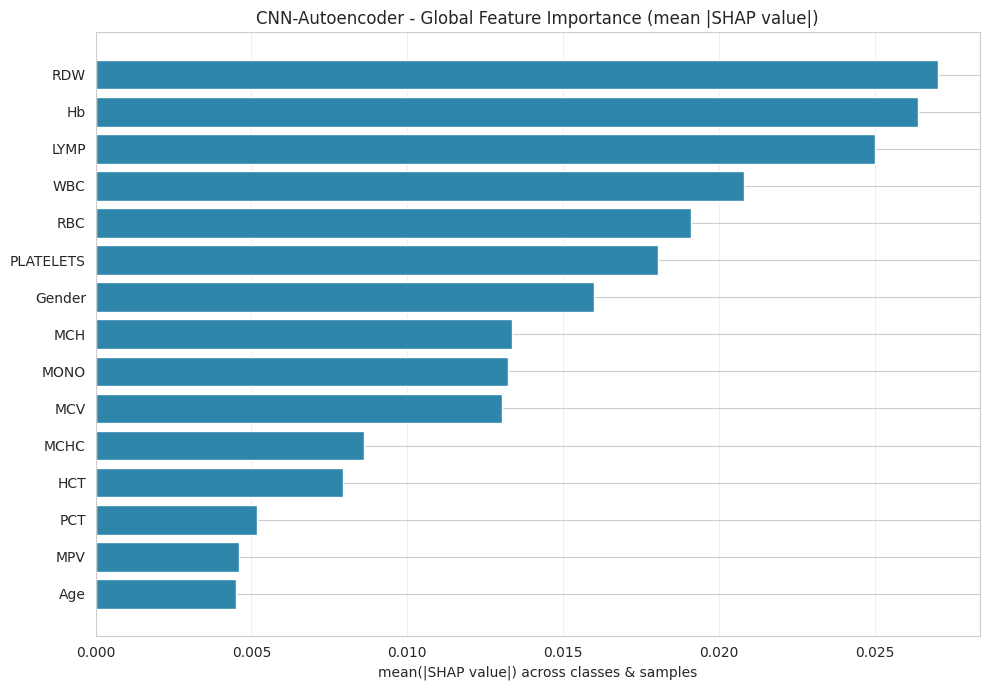

In [26]:
# ---------------------------------------------------------
# Global feature importance (mean |SHAP| across all classes)
# ---------------------------------------------------------
# Average |SHAP| across classes and samples -> single global ranking
mean_abs_shap = np.mean(np.abs(shap_arr), axis=(0, 1))   # (n_features,)
shap_global_df = pd.DataFrame({
    "Feature":    feature_names,
    "MeanAbsSHAP": mean_abs_shap
}).sort_values("MeanAbsSHAP", ascending=False)

print("Top 15 features by mean |SHAP| value:")
display(shap_global_df.head(15).round(4))

top_shap = shap_global_df.head(15).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top_shap["Feature"], top_shap["MeanAbsSHAP"], color="#2E86AB")
plt.title("CNN-Autoencoder - Global Feature Importance (mean |SHAP value|)")
plt.xlabel("mean(|SHAP value|) across classes & samples")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()



SHAP summary (beeswarm) for class: Anemia of Chronic Disease


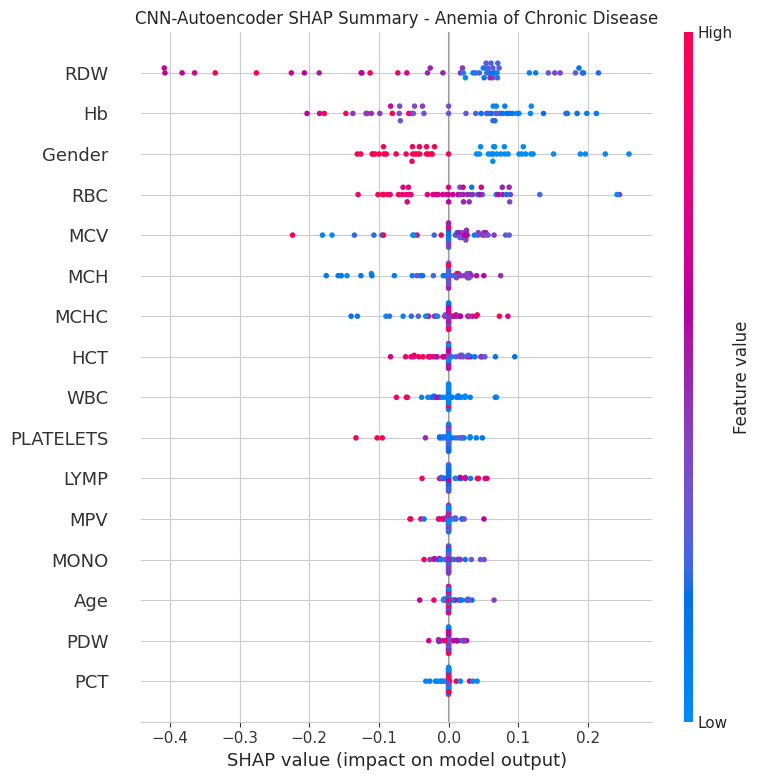


SHAP summary (beeswarm) for class: Bacterial Infections


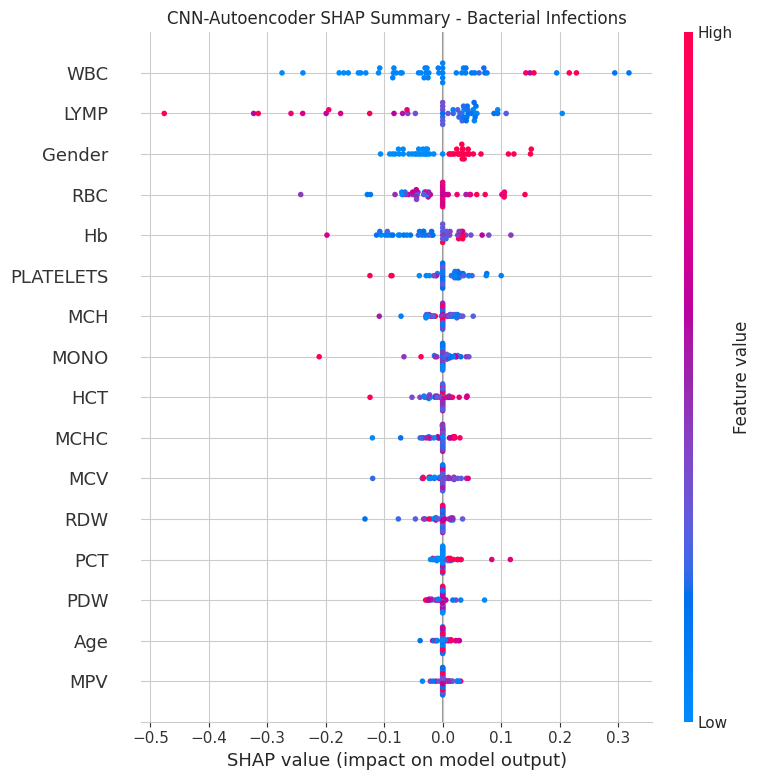


SHAP summary (beeswarm) for class: Beta-Thalassemia Minor


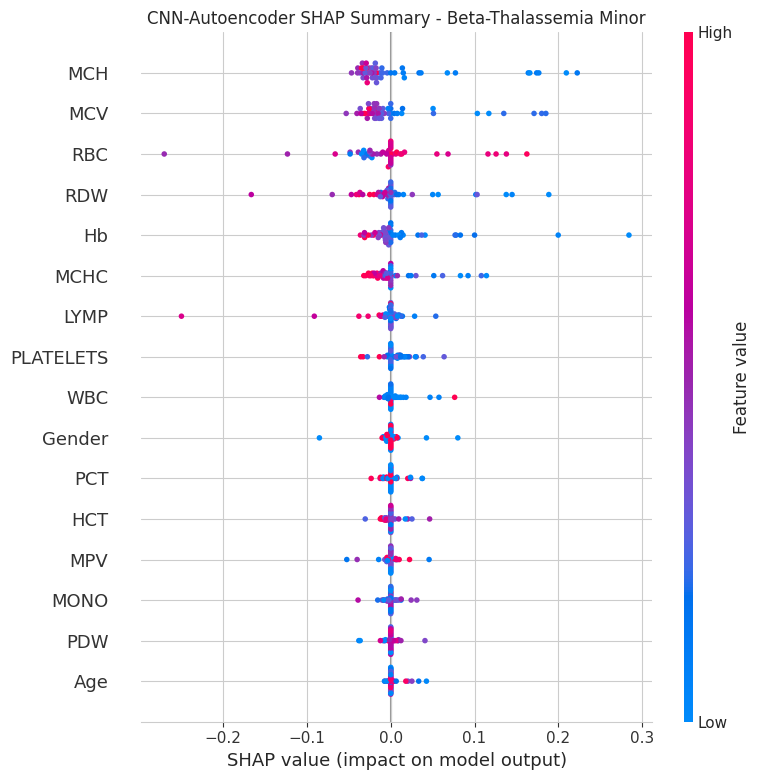


SHAP summary (beeswarm) for class: Chronic Leukemias


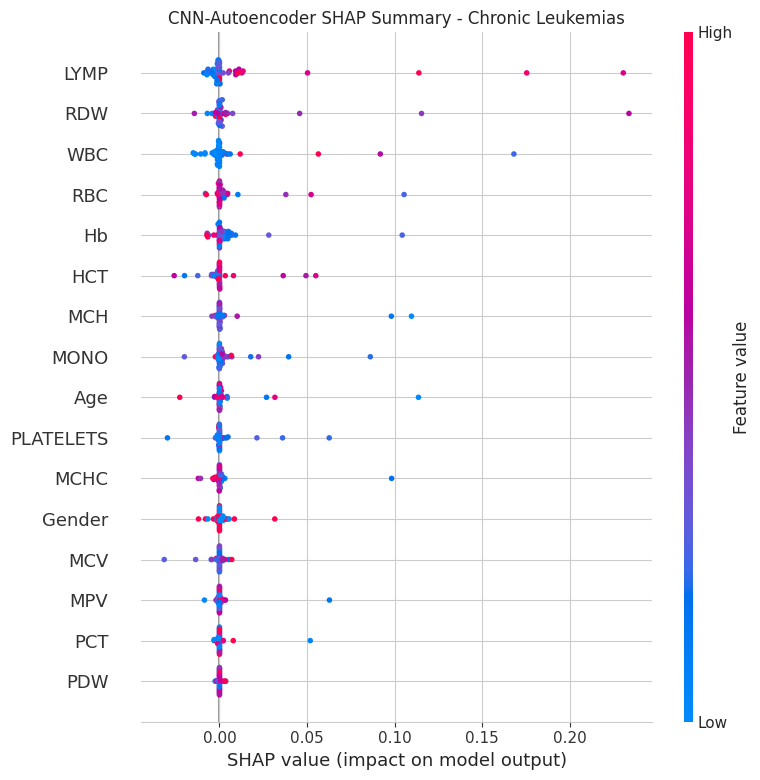


SHAP summary (beeswarm) for class: Infectious Mononucleosis


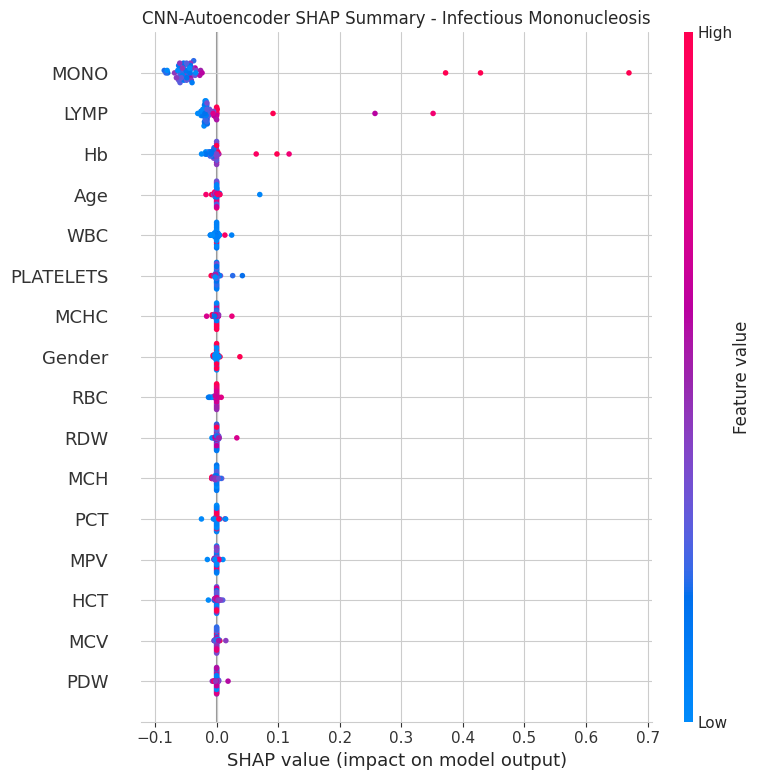


SHAP summary (beeswarm) for class: Iron Deficiency


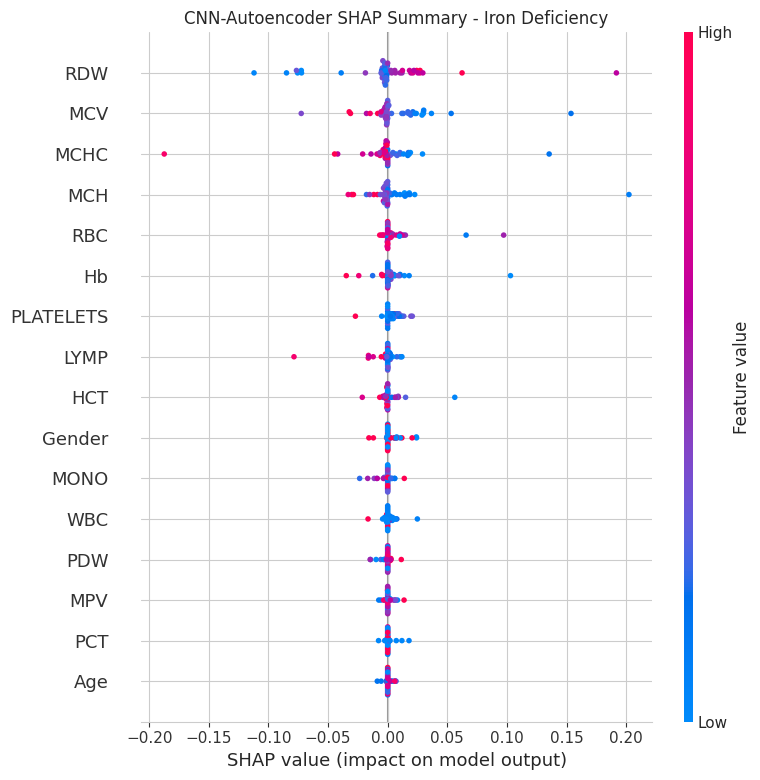


SHAP summary (beeswarm) for class: Leukocytosis


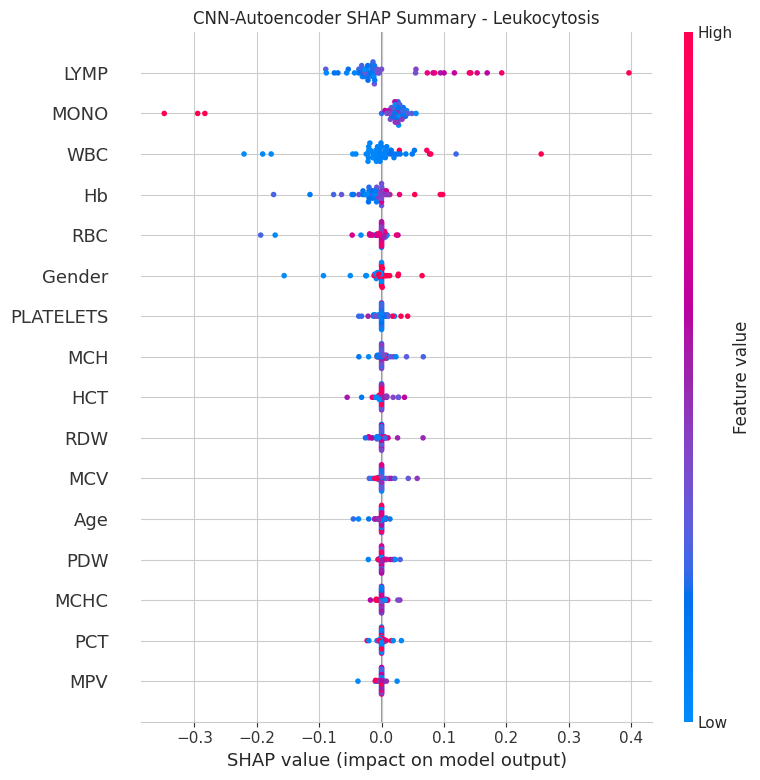


SHAP summary (beeswarm) for class: Leukopenia


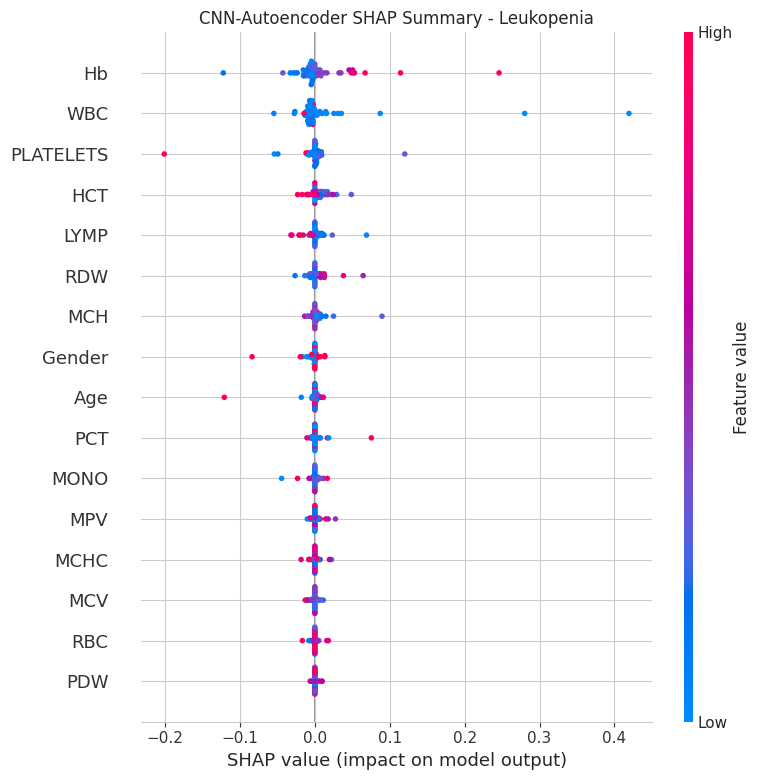


SHAP summary (beeswarm) for class: Microcytic Anemia


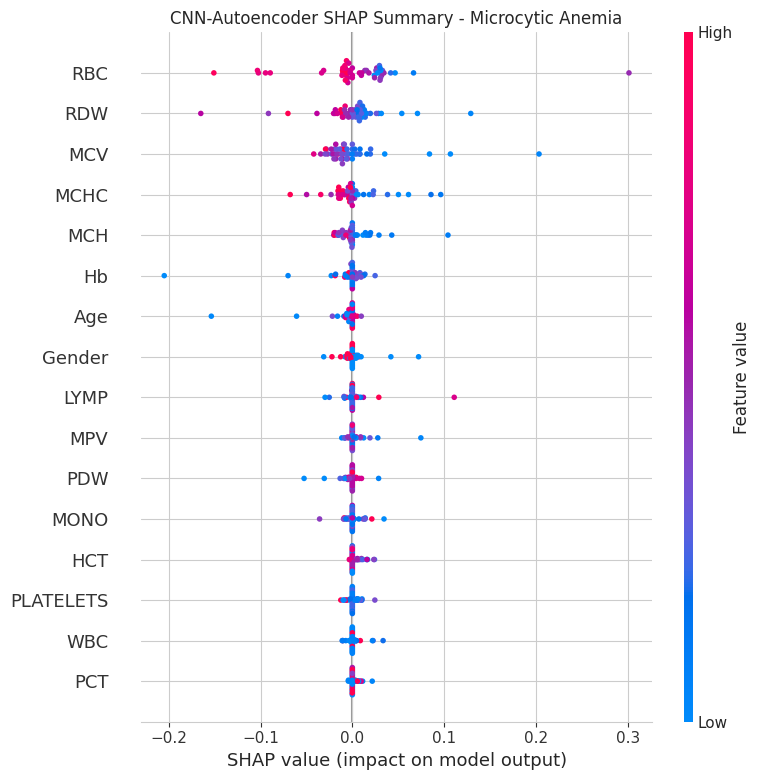


SHAP summary (beeswarm) for class: Normal


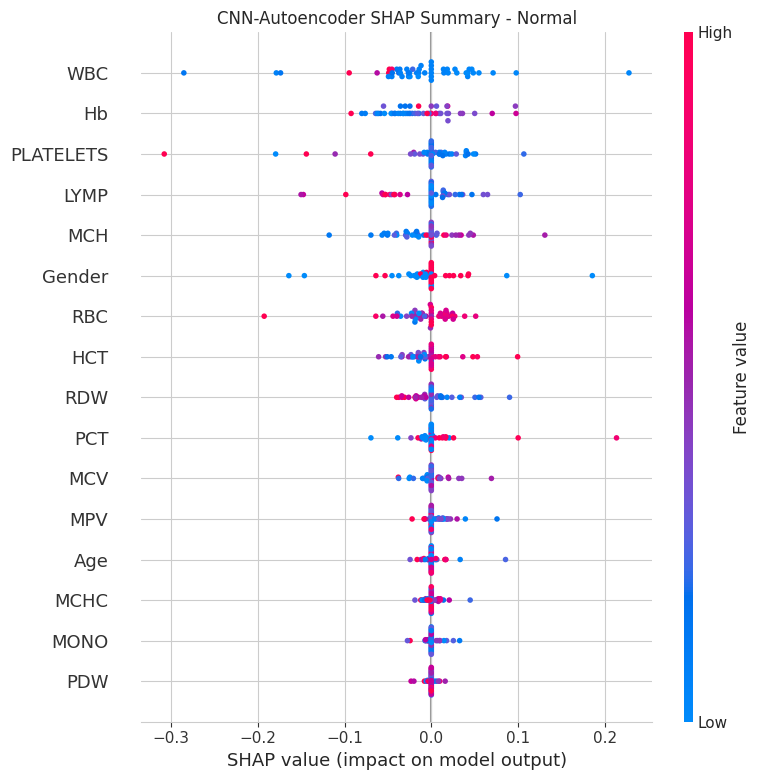


SHAP summary (beeswarm) for class: Normocytic Anemia


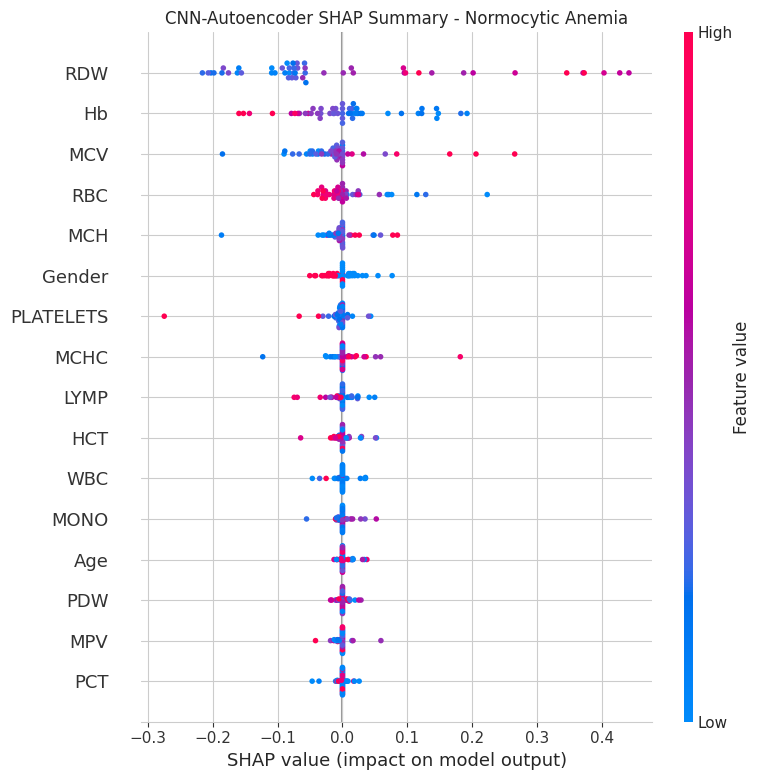


SHAP summary (beeswarm) for class: Polycythemia Vera


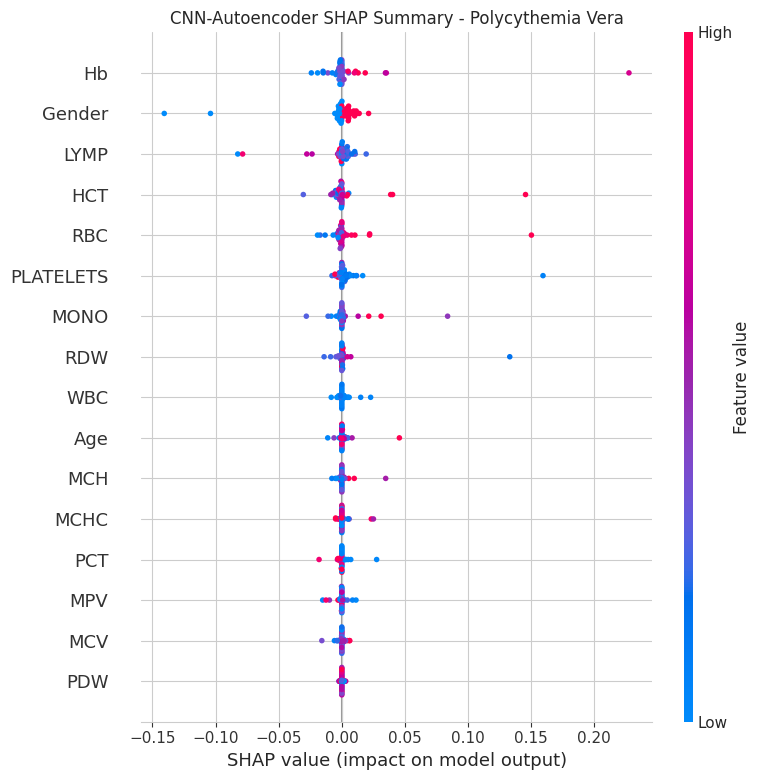


SHAP summary (beeswarm) for class: Thrombocytopenia


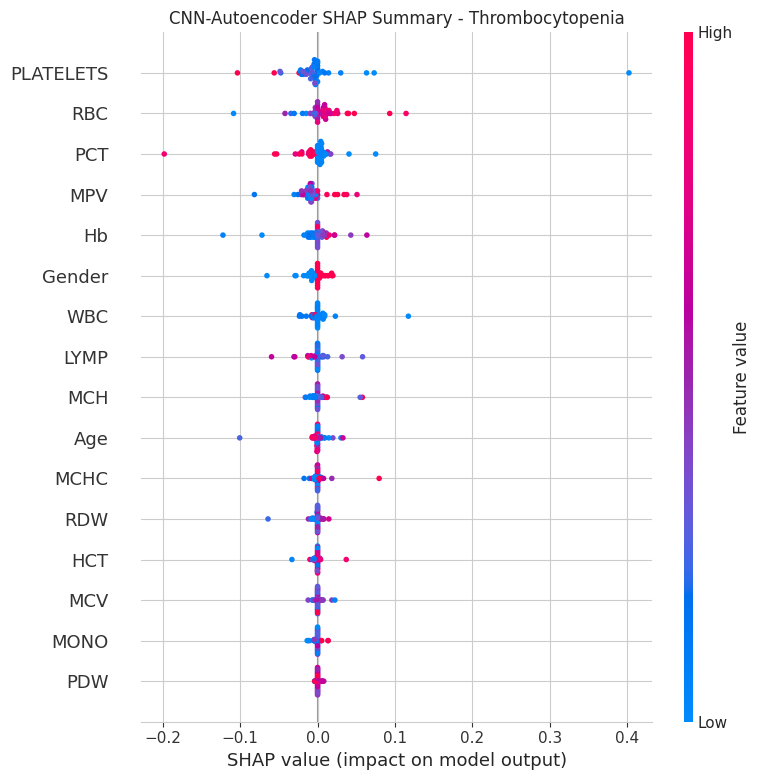


SHAP summary (beeswarm) for class: Thrombocytosis


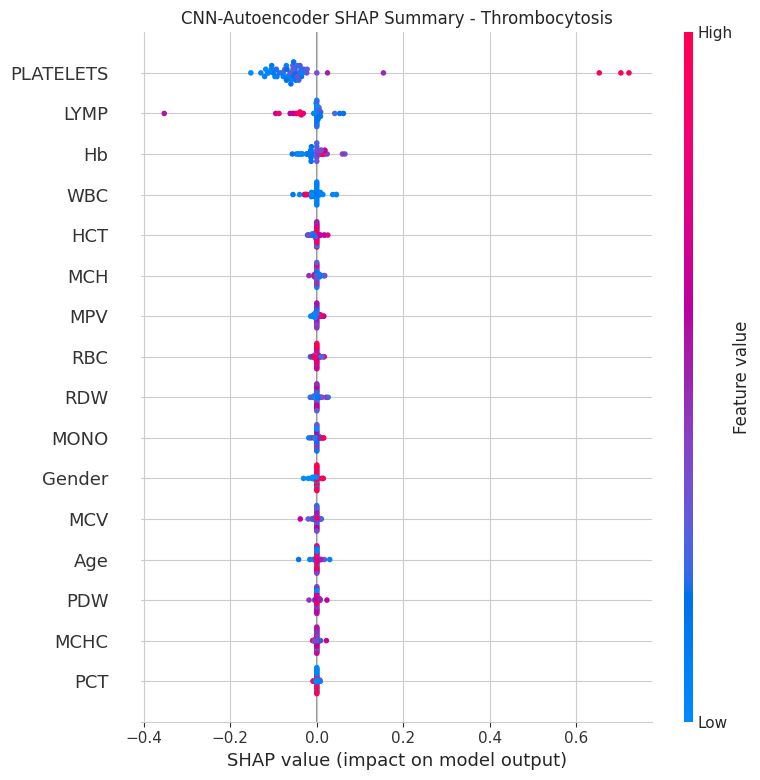


SHAP summary (beeswarm) for class: Viral Infections


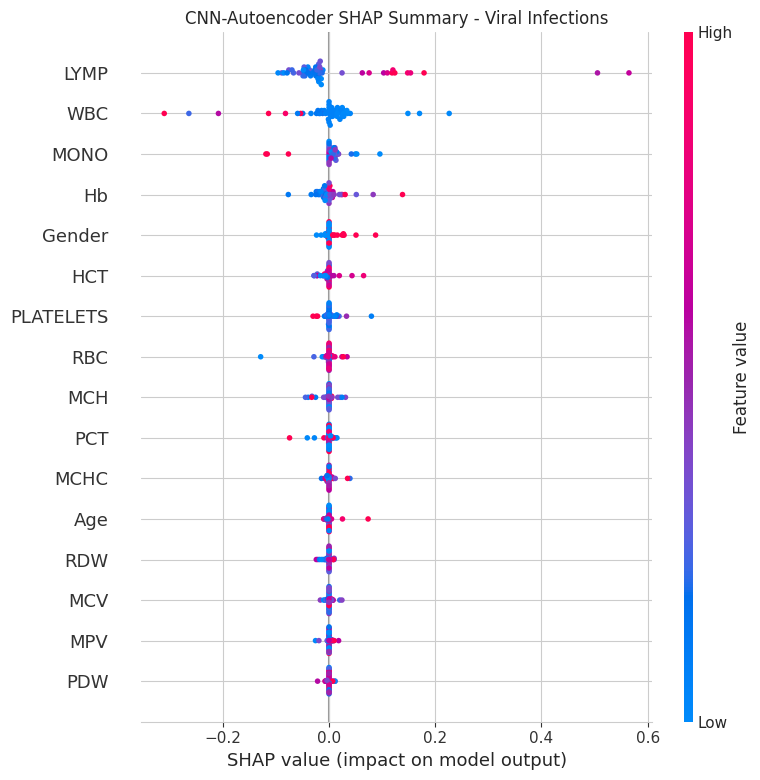

In [27]:
# ---------------------------------------------------------
# Beeswarm summary plot for each class
# Shows how high/low feature values push predictions up/down
# ---------------------------------------------------------
# X_sample is in MinMax-scaled space; for plotting we use it directly so that
# the colour scale (low/high feature value) is meaningful.
X_sample_df = pd.DataFrame(X_sample, columns=feature_names)

for i, cname in enumerate(class_names):
    print(f"\nSHAP summary (beeswarm) for class: {cname}")
    shap.summary_plot(
        shap_arr[i],
        X_sample_df,
        feature_names=feature_names,
        show=False
    )
    plt.title(f"CNN-Autoencoder SHAP Summary - {cname}")
    plt.tight_layout()
    plt.show()


### SHAP - Local Explanation (single patient)

Waterfall plot showing why CNN-Autoencoder predicted a particular diagnosis for one
sample from the test set.


Sample (subset index)  : 0
Sample (test index)    : 1133
True class             : Polycythemia Vera
Predicted class        : Polycythemia Vera
Predicted probability  : 0.8886


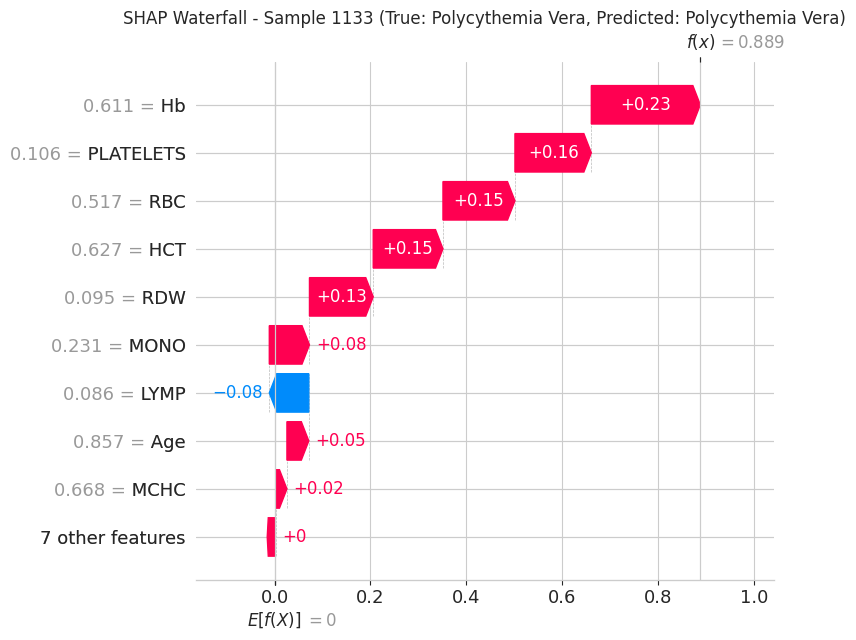

In [28]:
# ---------------------------------------------------------
# Local SHAP explanation: pick one sample and explain it
# ---------------------------------------------------------
sample_idx_in_subset = 0   # index within X_sample (the SHAP-explained subset)

# True / predicted labels for this sample
sample_flat   = X_sample[sample_idx_in_subset]
pred_probs    = predict_flat(sample_flat.reshape(1, -1))[0]
pred_class_idx = int(np.argmax(pred_probs))
pred_class_name = class_names[pred_class_idx]

# Map back to the original test index to get the true label
original_test_idx = test_idx[sample_idx_in_subset]
true_class_name = class_names[int(y_test[original_test_idx])]

print(f"Sample (subset index)  : {sample_idx_in_subset}")
print(f"Sample (test index)    : {original_test_idx}")
print(f"True class             : {true_class_name}")
print(f"Predicted class        : {pred_class_name}")
print(f"Predicted probability  : {pred_probs[pred_class_idx]:.4f}")

# Expected (base) value for the predicted class
expected_value = explainer_dl.expected_value
if isinstance(expected_value, (list, np.ndarray)):
    base_value = float(expected_value[pred_class_idx])
else:
    base_value = float(expected_value)

sample_shap = shap_arr[pred_class_idx][sample_idx_in_subset]

# Waterfall plot
shap.waterfall_plot(
    shap.Explanation(
        values=sample_shap,
        base_values=base_value,
        data=sample_flat,
        feature_names=feature_names
    ),
    show=False
)
plt.title(f"SHAP Waterfall - Sample {original_test_idx} "
          f"(True: {true_class_name}, Predicted: {pred_class_name})")
plt.tight_layout()
plt.show()


## LIME (Local Interpretable Model-agnostic Explanations) on CNN-Autoencoder

LIME explains a single prediction by fitting a simple, interpretable model
(linear regression) around that point in feature space. It treats the deep model
as a black box through the `predict_flat` wrapper.


In [29]:
# =========================================================
# LIME - Local explanations for CNN-Autoencoder
# =========================================================
import lime
import lime.lime_tabular

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_flat,
    feature_names=feature_names,
    class_names=class_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer ready.")


LIME explainer ready.


In [30]:
# ---------------------------------------------------------
# Explain a single test sample with LIME (Leukopenia case)
# ---------------------------------------------------------
target_disease = "Leukopenia"

if target_disease not in list(class_names):
    raise ValueError(f"'{target_disease}' not found in class_names. Available classes: {list(class_names)}")

target_class_idx = list(class_names).index(target_disease)

# Find all test samples whose TRUE label is Leukopenia
y_test_arr = np.asarray(y_test)
leuko_indices = np.where(y_test_arr == target_class_idx)[0]

if len(leuko_indices) == 0:
    raise ValueError(f"No test samples found with true label '{target_disease}'. Try another class.")

# Prefer a sample that the model also PREDICTS as Leukopenia
preds_all = np.argmax(predict_flat(X_test_flat), axis=1)
correct_leuko = [i for i in leuko_indices if preds_all[i] == target_class_idx]

if len(correct_leuko) > 0:
    sample_idx = int(correct_leuko[0])
    print(f"Using a correctly classified '{target_disease}' sample.")
else:
    sample_idx = int(leuko_indices[0])
    print(f"No correctly classified '{target_disease}' sample found; using a misclassified one.")

true_label = class_names[int(y_test_arr[sample_idx])]
pred_label = class_names[int(preds_all[sample_idx])]

print(f"Sample index : {sample_idx}")
print(f"True class   : {true_label}")
print(f"Predicted    : {pred_label}")

# top_labels=3 explains the 3 most likely classes for this sample
lime_exp = lime_explainer.explain_instance(
    data_row=X_test_flat[sample_idx],
    predict_fn=predict_flat,
    num_features=10,
    top_labels=3
)

# Show in notebook
lime_exp.show_in_notebook(show_table=True, show_all=False)


Using a correctly classified 'Leukopenia' sample.
Sample index : 18
True class   : Leukopenia
Predicted    : Leukopenia


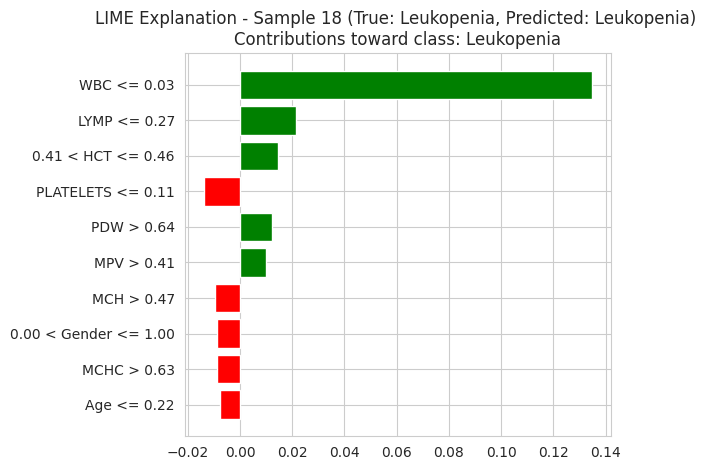


Top feature contributions for class 'Leukopenia':
  + WBC <= 0.03                                         weight = +0.1347
  + LYMP <= 0.27                                        weight = +0.0213
  + 0.41 < HCT <= 0.46                                  weight = +0.0147
  - PLATELETS <= 0.11                                   weight = -0.0138
  + PDW > 0.64                                          weight = +0.0124
  + MPV > 0.41                                          weight = +0.0101
  - MCH > 0.47                                          weight = -0.0096
  - 0.00 < Gender <= 1.00                               weight = -0.0089
  - MCHC > 0.63                                         weight = -0.0088
  - Age <= 0.22                                         weight = -0.0077


In [31]:
# ---------------------------------------------------------
# Static matplotlib version of the LIME explanation
# Showing explanation for the Leukopenia class specifically
# ---------------------------------------------------------
pred_class_idx = int(preds_all[sample_idx])

# Explain the LIME contributions toward the "Leukopenia" class
explain_label_idx = target_class_idx  # always show why model thinks this is Leukopenia
fig = lime_exp.as_pyplot_figure(label=explain_label_idx)
plt.title(f"LIME Explanation - Sample {sample_idx} "
          f"(True: {true_label}, Predicted: {class_names[pred_class_idx]}) "
          f"\nContributions toward class: {class_names[explain_label_idx]}")
plt.tight_layout()
plt.show()

# Print feature contributions as text
print(f"\nTop feature contributions for class '{class_names[explain_label_idx]}':")
for feat, weight in lime_exp.as_list(label=explain_label_idx):
    direction = "+" if weight > 0 else "-"
    print(f"  {direction} {feat:50s}  weight = {weight:+.4f}")
